# Q1  Multi-Task CNN on Fashion-MNIST

### Data Loading and Preprocessing

##### Dataset Loading

In [1]:
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

def load_fashion_data():
  """
    Load FashionMNIST dataset and split into training, validation, and test sets.
    Returns:
        train_dataset: Training dataset (90% of original training set)
        val_dataset: Validation dataset (10% of original training set)
        test_dataset: Test dataset
  """
  full_train_dataset = torchvision.datasets.FashionMNIST(
      root='./data',
      train=True,
      download=True,
      transform=transforms.ToTensor()
  )

  test_dataset = torchvision.datasets.FashionMNIST(
      root='./data',
      train=False,
      download=True,
      transform=transforms.ToTensor()
  )

  train_size = int(0.9 * len(full_train_dataset))
  val_size = len(full_train_dataset) - train_size
  train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size])

  return train_dataset, val_dataset, test_dataset

In [2]:
train_base_dataset, val_base_dataset, test_base_dataset = load_fashion_data()

print("CHECK")
print("=====")
print("Number of training examples:", len(train_base_dataset))
print("Number of validation examples:", len(val_base_dataset))
print("Number of test examples:", len(test_base_dataset))
print("Image size:", train_base_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 209kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.89MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.7MB/s]

CHECK
=====
Number of training examples: 54000
Number of validation examples: 6000
Number of test examples: 10000
Image size: torch.Size([1, 28, 28])


##### Custom Dataset Class

In [3]:
from torch.utils.data import Dataset

class FashionMNISTDataset(Dataset):
  """
    Custom Dataset for FashionMNIST that normalizes images and computes ink target.
    Each item returned is a tuple (image, label, ink_target).
  """
  def __init__(self, data_set,mean,std,train=True):
    """
      Args:
          data_set: Dataset of images and labels
          mean: Mean of the dataset
          std: Standard deviation of the dataset
    """
    self.data_set=data_set
    self.mean=mean
    self.std=std
    self.train=train

    self.base_transform=transforms.Normalize((mean,), (std,))

  def __len__(self):
    """
      Returns the length of the dataset
    """
    return len(self.data_set)

  def __getitem__(self, idx):
    """
      Args:
          idx: Index of the item to retrieve
      Returns:
          img: Normalized image tensor
          label: Corresponding label
          ink_target: Normalized ink target value
    """
    image,label=self.data_set[idx]

    img=self.base_transform(image)
    ink_target=img.mean().item()
    ink_target=(ink_target-self.mean)/self.std

    return img,label,ink_target

##### Augmentations

In [4]:
import random
import torchvision.transforms.functional as TF

class AugmentedFashionMNISTDataset(FashionMNISTDataset):
  """
    Custom Dataset for FashionMNIST with data augmentation for training set.
    Each item returned is a tuple (image, label, ink_target).
  """
  def __getitem__(self, idx):
    """
      Args:
          idx: Index of the item to retrieve
      Returns:
          img: Augmented and normalized image tensor
          label: Corresponding label
          ink_target: Normalized ink target value
    """
    img,label=self.data_set[idx]
    if self.train:
      if random.random() > 0.5:
        img=TF.crop(img,top=random.randint(0,2),left=random.randint(0,2),height=26,width=26)
        img=TF.resize(img,(28,28))
      if random.random() > 0.5:
        angle=random.uniform(-10,10)
        img=TF.rotate(img,angle)

    img=self.base_transform(img)
    ink_target=img.mean().item()
    ink_target=(ink_target-self.mean)/self.std

    return img,label,ink_target

full_raw_train_dataset=torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transforms.ToTensor()
)
all_images=torch.stack([full_raw_train_dataset[i][0] for i in range(len(full_raw_train_dataset))])
mean=all_images.mean().item()
std=all_images.std().item()

train_dataset=AugmentedFashionMNISTDataset(train_base_dataset,mean,std,train=True)
val_dataset=AugmentedFashionMNISTDataset(val_base_dataset,mean,std,train=False)
test_dataset=AugmentedFashionMNISTDataset(test_base_dataset,mean,std,train=False)

print("CHECK")
print("=====")
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(val_dataset))
print("Number of test examples:", len(test_dataset))
print("Image size:", train_dataset[0][0].shape)


CHECK
=====
Number of training examples: 54000
Number of validation examples: 6000
Number of test examples: 10000
Image size: torch.Size([1, 28, 28])


In [5]:
train_loader=DataLoader(train_dataset,batch_size=128,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=128,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=128,shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

##### Sample Images

In [6]:
import matplotlib.pyplot as plt

def show_images(images,labels,ink_values):
  """
    Display a grid of images with their labels and ink values.
    Args:
        images: Batch of image tensors
        labels: Corresponding labels
        ink_values: Corresponding ink target values
  """
  img=torchvision.utils.make_grid(images)
  img=img*std+mean
  np_img=img.numpy()
  plt.figure(figsize=(8,4))
  plt.imshow(np.transpose(np_img,(1,2,0)),cmap='gray')
  plt.axis('off')
  plt.show()

  print(' '.join(f'{classes[labels[j]]:8s}' for j in range(8)))
  print(' '.join(f'{ink_values[j]:<9.2f}' for j in range(8)))

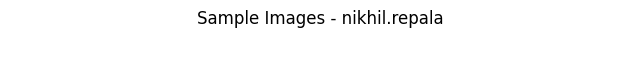

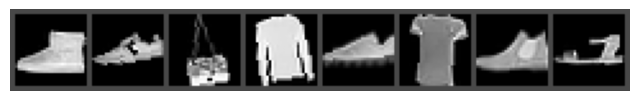

Ankle boot Sneaker  Bag      Pullover Sneaker  T-shirt/top Ankle boot Sandal  
-0.61     -1.88     -1.84     1.05      -1.61     -0.73     -1.27     -2.22    


In [7]:
data_sampels=iter(train_loader)
images,labels,ink_targets=next(data_sampels)
plt.figure(figsize=(8,0.5))
plt.title("Sample Images - nikhil.repala")
plt.axis('off')
show_images(images[:8],labels[:8],ink_targets[:8])

### Model Implementation: Multi-Task CNN

#####  Model

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class MultiTaskCNN(nn.Module):
  """
    Multi-task CNN for classification and regression on FashionMNIST dataset.
    Outputs class logits and ink target regression value.
  """
  def __init__(self,NIC=1,NF=32,dropout_rate=0.3,return_feat=False):
    """
      Args:
          NIC: Number of input channels
          NF: Number of base feature maps
          dropout_rate: Dropout rate for regularization
          return_feat: If True, return intermediate feature maps
    """
    super(MultiTaskCNN,self).__init__()
    self.return_feat=return_feat

    self.enc1=nn.Sequential(
       nn.Conv2d(NIC,NF,kernel_size=3,padding=1),
       nn.BatchNorm2d(NF),
       nn.ReLU(inplace=True),
       nn.MaxPool2d(2)
    )
    self.enc2=nn.Sequential(
       nn.Conv2d(NF,NF*2,kernel_size=3,padding=1),
       nn.BatchNorm2d(NF*2),
       nn.ReLU(inplace=True),
       nn.MaxPool2d(2)
    )
    self.enc3=nn.Sequential(
       nn.Conv2d(NF*2,NF*4,kernel_size=3,padding=1),
       nn.BatchNorm2d(NF*4),
       nn.ReLU(inplace=True),
       nn.MaxPool2d(2)
    )

    feat_dim=NF*4
    self.dropout=nn.Dropout(dropout_rate)
    self.global_pool=nn.AdaptiveAvgPool2d((1,1))

    self.classifier=nn.Sequential(
        nn.Linear(feat_dim,feat_dim//2),
        nn.ReLU(inplace=True),
        nn.Dropout(dropout_rate),
        nn.Linear(feat_dim//2,10)
    )

    self.regressor=nn.Sequential(
        nn.Linear(feat_dim,feat_dim//2),
        nn.ReLU(inplace=True),
        nn.Dropout(dropout_rate),
        nn.Linear(feat_dim//2,1)
    )

    self.__init__weights()

  def __init__weights(self):
    """
      Initialize weights of convolutional and linear layers using Kaiming normal initialization.
    """
    for m in self.():
      if isinstance(m,nn.Conv2d) or isinstance(m,nn.Linear):
        nn.init.kaiming_normal_(m.weight,nonlinearity='relu')
        if getattr(m,'bias',None) is not None:
          nn.init.zeros_(m.bias)

  def forward(self,x,return_feature_map=False):
    """
      Forward pass of the network.
      Args:
          x: Input tensor
          return_feature_map: If True, return intermediate feature maps
      Returns:
          logits: Class logits
          reg_out: Ink target regression value
          feats: Dictionary of intermediate feature maps (if requested)
    """
    feats={}
    x1=self.enc1(x)
    feats['enc1']=x1
    x2=self.enc2(x1)
    feats['enc2']=x2
    x3=self.enc3(x2)
    feats['enc3']=x3

    out=self.dropout(x3)
    out=self.global_pool(out)
    out=torch.flatten(out,1)

    logits=self.classifier(out)
    reg_out=self.regressor(out)

    if return_feature_map or self.return_feat:
      return logits,reg_out,feats
    else:
      return logits,reg_out

##### Joint Loss Helper

In [10]:
ce_loss=nn.CrossEntropyLoss()
mse_loss=nn.MSELoss()

def compute_loss(logits,reg_out,labels,reg_targets,lambda1=1.0,lambda2=1.0):
  """
    Compute combined loss for classification and regression tasks.
    Args:
        logits: Class logits from the model
        reg_out: Regression output from the model
        labels: True class labels
        reg_targets: True regression targets
        lambda1: Weight for classification loss
        lambda2: Weight for regression loss
    Returns:
        total: Combined loss
        losses: Dictionary of individual losses
  """
  ce_loss_val=ce_loss(logits,labels)
  if reg_targets.dim()==1:
    reg_targets=reg_targets.unsqueeze(1)
  mse_loss_val=mse_loss(reg_out,reg_targets)
  total=(ce_loss_val*lambda1)+(mse_loss_val*lambda2)
  return total,{"ce_loss":ce_loss_val.item(),"mse_loss":mse_loss_val.item(),"total_loss":total.item()}

##### Sample Test

In [11]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model=MultiTaskCNN()
model.to(device)

batch=next(iter(train_loader))
images,labels,ink_targets=batch
images=images.to(device)
labels=labels.to(device)
ink_targets=ink_targets.to(device).float().unsqueeze(1)

logits,reg_out,feats=model(images,return_feature_map=True)

print("Logits shape :",logits.shape)
print("Regression output shape:",reg_out.shape)
print("Features enc1 shape:",feats['enc1'].shape)

total_loss,losses=compute_loss(logits,reg_out,labels,ink_targets)
print("Losses:",losses)

Logits shape : torch.Size([128, 10])
Regression output shape: torch.Size([128, 1])
Features enc1 shape: torch.Size([128, 32, 14, 14])
Losses: {'ce_loss': 3.1319780349731445, 'mse_loss': 12.553155899047852, 'total_loss': 15.685133934020996}


Experiment with different values of λ1 and λ2

In [12]:
import torch.optim as optim
from tqdm import tqdm

def train_model(model,train_loader,val_loader,optimizer,lambda1=1.0,lambda2=1.0,epochs=5):
  """
    Train the model.
    Args:
        model: The neural network model to train
        train_loader: DataLoader for training data
        val_loader: DataLoader for validation data
        optimizer: Optimizer for training
        lambda1: Weight for classification loss
        lambda2: Weight for regression loss
        epochs: Number of training epochs
    Returns:
        val_acc: Validation accuracy after training
        mse: Mean Squared Error on validation set after training
  """
  ce_loss_fn=nn.CrossEntropyLoss()
  mse_loss_fn=nn.MSELoss()

  for epoch in range(epochs):
    model.train()
    total_loss=0.0
    correct=0
    total=0

    for images,labels,ink_targets in tqdm(train_loader,desc=f"Epoch {epoch+1}/{epochs}"):
      images=images.to(device)
      labels=labels.to(device)
      ink_targets=ink_targets.to(device).float()

      optimizer.zero_grad()
      cls_out,reg_out=model(images)
      loss,losses=compute_loss(cls_out,reg_out,labels,ink_targets,lambda1,lambda2)
      loss.backward()
      optimizer.step()

      total_loss+=loss.item()
      preds=torch.argmax(cls_out,dim=1)
      correct+=(preds==labels).sum().item()
      total+=labels.size(0)

    acc=correct/total
    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}, Accuracy: {acc*100:.2f}%")

    model.eval()
    val_loss=0.0
    val_acc=0
    mse_accum=0.0
    with torch.no_grad():
      for images,labels,ink_targets in val_loader:
        images=images.to(device)
        labels=labels.to(device)
        ink_targets=ink_targets.to(device).float()

        cls_out,reg_out=model(images)
        loss,losses=compute_loss(cls_out,reg_out,labels,ink_targets,lambda1,lambda2)
        val_loss+=loss.item()
        preds=torch.argmax(cls_out,dim=1)
        val_acc+=(preds==labels).sum().item()
        mse_accum+=F.mse_loss(reg_out.squeeze(),ink_targets,reduction='sum').item()

      val_acc=val_acc/len(val_loader.dataset)
      mse=mse_accum/len(val_loader.dataset)
      print(f"Validation - Loss: {val_loss/len(val_loader):.4f}, Accuracy: {val_acc*100:.2f}%")
  return val_acc,mse

In [ ]:
lambda_pairs = [(1,1), (2,1), (1,2), (0.5,1)]
results = []

for lambda1, lambda2 in lambda_pairs:
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MultiTaskCNN()
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    val_acc, mse = train_model(model, train_loader, val_loader, optimizer, lambda1, lambda2, epochs=5)
    results.append((val_acc, mse))

Epoch 1/5: 100%|██████████| 422/422 [02:06<00:00,  3.34it/s]


Epoch 1/5 - Loss: 1.0735, Accuracy: 67.22%
Validation - Loss: 0.5783, Accuracy: 81.25%


Epoch 2/5: 100%|██████████| 422/422 [02:11<00:00,  3.20it/s]


Epoch 2/5 - Loss: 0.6377, Accuracy: 79.49%
Validation - Loss: 0.4111, Accuracy: 85.68%


Epoch 3/5: 100%|██████████| 422/422 [02:12<00:00,  3.20it/s]


...

Epoch 3/5 - Loss: 0.3190, Accuracy: 81.24%
Validation - Loss: 0.1964, Accuracy: 86.23%


Epoch 4/5: 100%|██████████| 422/422 [02:11<00:00,  3.20it/s]


Epoch 4/5 - Loss: 0.2865, Accuracy: 83.00%
Validation - Loss: 0.1923, Accuracy: 86.52%


Epoch 5/5: 100%|██████████| 422/422 [02:12<00:00,  3.18it/s]


Epoch 5/5 - Loss: 0.2699, Accuracy: 84.17%
Validation - Loss: 0.1971, Accuracy: 85.65%


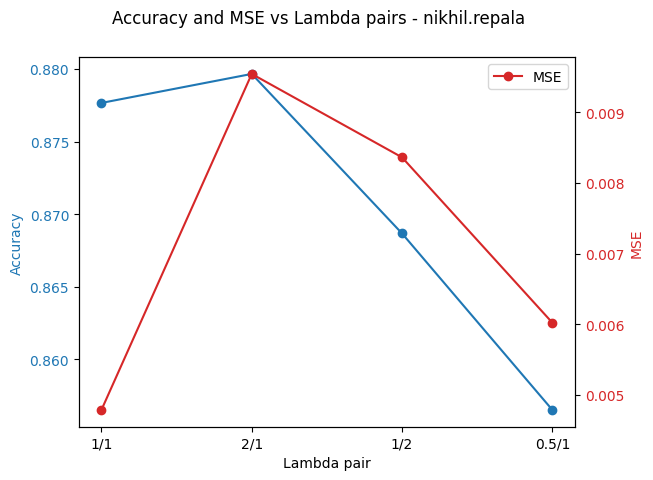

In [ ]:
ratios=[f"{lambda1}/{lambda2}" for lambda1,lambda2 in lambda_pairs]
accs=[acc for acc,_ in results]
mses=[mse for _,mse in results]


fig,ax1=plt.subplots()
ax1.set_xlabel("Lambda pair")
ax1.set_ylabel("Accuracy",color='tab:blue')
ax1.plot(ratios,accs,marker='o',color='tab:blue',label='Accuracy')
ax1.tick_params(axis='y',labelcolor='tab:blue')

ax2=ax1.twinx()
ax2.set_ylabel("MSE",color='tab:red')
ax2.plot(ratios,mses,marker='o',color='tab:red',label='MSE')
ax2.tick_params(axis='y',labelcolor='tab:red')

fig.suptitle("Accuracy and MSE vs Lambda pairs - nikhil.repala")
plt.legend()
plt.show()

### Discussion: Effect of λ₁ and λ₂ on Multi-Task Learning Performance

The graph compares **classification accuracy** (blue) and **regression MSE** (red) for different λ₁:λ₂ weight ratios in the joint loss function.

- With equal weights (**1:1**), both tasks perform reasonably well, showing balanced learning with better mse and accuarcy.
- Increasing classification weight (**2:1**) gives the **highest accuracy (≈0.88)** but **worse MSE (≈0.0095)** — the model prioritizes classification, reducing regression precision.  
- Increasing regression weight (**1:2**) improves MSE slightly but lowers accuracy.  
- The lowest λ₁ (**0.5:1**) further reduces accuracy, even though MSE improves to ≈0.0060.


so,

There is a trade-off between the two objectives — higher λ₁ favors classification accuracy, while higher λ₂ improves regression MSE. The **1:1 ratio** provides a good overall balance for this multi-task CNN.


### Hyperparameter Tuning and wandb Logging

In [13]:
import wandb

wandb.login()

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: nikhilrepala8074 (nikhil_r_8074-iiit-hyderabad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [14]:
def train_and_log(config=None):
  """
    Train the model with given configuration and log metrics to Weights & Biases.
    Args:
        config: Configuration dictionary for training parameters
    Returns:
        model: Trained model
  """
  with wandb.init(project="SMAI-MultiTask-FashionMNIST",
                  config=config,
                  name=config["run_name"] if "run_name" in config else None,
                  group=config["group"] if "group" in config else None):
    config=wandb.config
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

    train_loader=DataLoader(train_dataset,batch_size=config.batch_size,shuffle=True)
    val_loader=DataLoader(val_dataset,batch_size=config.batch_size,shuffle=False)

    model=MultiTaskCNN(
        NF=config.NF,
        dropout_rate=config.dropout_rate
    )
    model.to(device)

    if config.optimizer=="Adam":
      optimizer=optim.Adam(model.parameters(),lr=config.lr)
    elif config.optimizer=="SGD":
      optimizer=optim.SGD(model.parameters(),lr=config.lr)
    elif config.optimizer=="AdamW":
      optimizer=optim.AdamW(model.parameters(),lr=config.lr)

    ce_loss_fn=nn.CrossEntropyLoss()
    mse_loss_fn=nn.MSELoss()

    for epoch in range(config.epochs):
      model.train()
      total_loss=0.0
      ce_total=0.0
      mse_total=0.0
      correct=0
      total=0

      for images,labels,ink_targets in tqdm(train_loader,desc=f"Epoch {epoch+1}/{config.epochs}"):
        images=images.to(device)
        labels=labels.to(device)
        ink_targets=ink_targets.to(device).float()

        optimizer.zero_grad()
        cls_out,reg_out=model(images)
        loss,losses=compute_loss(cls_out,reg_out,labels,ink_targets,config.lambda1,config.lambda2)
        loss.backward()
        optimizer.step()

        total_loss+=loss.item()
        ce_total+=losses['ce_loss']
        mse_total+=losses['mse_loss']
        preds=torch.argmax(cls_out,dim=1)
        correct+=(preds==labels).sum().item()
        total+=labels.size(0)

      train_acc=correct/total
      wandb.log({
          "Train Total Loss":total_loss/len(train_loader),
          "Train CE Loss":ce_total/len(train_loader),
          "Train MSE Loss":mse_total/len(train_loader),
          "Train Accuracy":train_acc,
          "epoch":epoch+1
      })

      model.eval()
      val_loss=0.0
      val_ce=0.0
      val_mse=0.0
      val_acc=0
      mae_accum=0.0
      mse_accum=0.0
      with torch.no_grad():
        for images,labels,ink_targets in val_loader:
          images=images.to(device)
          labels=labels.to(device)
          ink_targets=ink_targets.to(device).float()

          cls_out,reg_out=model(images)
          loss,losses=compute_loss(cls_out,reg_out,labels,ink_targets,config.lambda1,config.lambda2)
          val_loss+=loss.item()
          val_ce+=losses['ce_loss']
          val_mse+=losses['mse_loss']

          preds=torch.argmax(cls_out,dim=1)
          val_acc+=(preds==labels).sum().item()
          mae_accum+=torch.mean(torch.abs(reg_out.squeeze()-ink_targets)).item()
          mse_accum+=F.mse_loss(reg_out.squeeze(),ink_targets,reduction='sum').item()

      val_acc=val_acc/len(val_loader.dataset)
      rmse=(mse_accum/len(val_loader.dataset))**0.5
      mae=mae_accum/len(val_loader.dataset)
      wandb.log({
           "Validation Total Loss":val_loss/len(val_loader),
           "Validation CE Loss":val_ce/len(val_loader),
           "Validation MSE Loss":val_mse/len(val_loader),
           "Validation Accuracy":val_acc,
           "Validation MAE":mae,
           "Validation RMSE":rmse,
      })

    print(f"Run finished for config {config} , val_acc={val_acc:.4f},rmse={rmse:.4f}")
    return model

##### Lamba Weight Experiments

In [15]:
num_epochs=20

lambda_group=[
    {
        "run_name":"lamda_1_1","lambda1":1.0,"lambda2":1.0,
        "lr":1e-3,"dropout_rate":0.3,"NF":32,"batch_size":64,
        "epochs":num_epochs,"optimizer":"Adam",
        "group":"Lambda Weight Experiments"
    },
    {
        "run_name":"lamda_2_1","lambda1":2.0,"lambda2":1.0,
        "lr":1e-3,"dropout_rate":0.3,"NF":32,"batch_size":64,
        "epochs":num_epochs,"optimizer":"Adam",
        "group":"Lambda Weight Experiments"
    },
    {
        "run_name":"lamda_1_2","lambda1":1.0,"lambda2":2.0,
        "lr":1e-3,"dropout_rate":0.3,"NF":32,"batch_size":64,
        "epochs":num_epochs,"optimizer":"Adam",
        "group":"Lambda Weight Experiments"
    },
    {
        "run_name":"lamda_0.5_1","lambda1":0.5,"lambda2":1.0,
        "lr":1e-3,"dropout_rate":0.3,"NF":32,"batch_size":64,
        "epochs":num_epochs,"optimizer":"Adam",
        "group":"Lambda Weight Experiments"
    }
]

In [ ]:
for cfg in lambda_group:
  print(f"Starting run for config {cfg['run_name']} in group {cfg['group']}")
  train_and_log(cfg)

Starting run for config lamda_1_1 in group Lambda Weight Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:28<00:00, 29.14it/s]


Run finished for config {'run_name': 'lamda_1_1', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Lambda Weight Experiments'} , val_acc=0.9237,rmse=0.0943


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Validation Accuracy,▁▄▄▅▆▆▇▆▇▇▇▇▇▇██████
Validation CE Loss,█▅▅▃▃▃▂▂▂▂▂▂▂▂▁▁▂▁▁▁
Validation MAE,▅▂▅▁▅▆▅▃▃█▄▁▄▃▁▃▅▂▃▃
Validation MSE Loss,▅▂▇▁▅▆▅▂▃█▃▁▄▃▁▂▅▂▃▃
Validation RMSE,▆▃▇▁▆▇▆▃▃█▄▁▄▃▂▃▆▂▃▃
Validation Total Loss,█▅▅▃▃▃▂▂▂▂▂▂▂▂▁▁▂▁▁▁
+1,...


Starting run for config lamda_2_1 in group Lambda Weight Experiments


...

Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇█████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▅▄▆▆▇▇▇▇▇▇█▇██▇███
Validation CE Loss,█▆▄▆▃▃▂▂▂▂▂▂▁▂▁▁▁▁▁▁
Validation MAE,▅▃▇▃▅█▃▃▄▃▁▂▅▃▂▁▂▁▃▁
Validation MSE Loss,▅▃▆▃▄█▂▃▃▂▁▂▄▃▂▁▁▁▂▁
Validation RMSE,▆▃▇▃▅█▃▃▃▃▁▂▅▃▂▁▂▁▃▁
Validation Total Loss,█▆▄▅▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁
+1,...


Starting run for config lamda_0.5_1 in group Lambda Weight Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:31<00:00, 26.53it/s]


Run finished for config {'run_name': 'lamda_0.5_1', 'lambda1': 0.5, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Lambda Weight Experiments'} , val_acc=0.9233,rmse=0.0652


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇█████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▃▃▆▅▇▇▇▇▇▇▇██▇▇███
Validation CE Loss,█▆▆▆▃▄▂▂▂▂▂▂▂▁▁▂▁▁▁▁
Validation MAE,▅▃▆▅▅▂▄▂▃▄▅█▃▂▅▅▁▁▁▁
Validation MSE Loss,▆▃▅▄▅▂▄▂▂▄▅█▂▂▅▄▁▁▁▁
Validation RMSE,▆▃▆▅▆▂▄▂▃▄▅█▃▂▆▅▁▁▁▁
Validation Total Loss,█▅▆▆▃▄▂▂▂▂▂▂▂▁▂▂▁▁▁▁
+1,...


##### Dropout Rate and Learning Rate Experiment

In [ ]:
drop_lr_grouo=[
    {
        "run_name": "drop_0.2_lr1e-3", "lambda1": 1.0, "lambda2": 1.0,
        "lr": 1e-3, "dropout_rate": 0.2, "NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Dropout & LR Experiments"
    },
    {
        "run_name": "drop_0.4_lr1e-3", "lambda1": 1.0, "lambda2": 1.0,
        "lr": 1e-3, "dropout_rate": 0.4, "NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Dropout & LR Experiments"
    },
    {
        "run_name": "drop_0.3_lr5e-4", "lambda1": 1.0, "lambda2": 1.0,
        "lr":5e-4, "dropout_rate": 0.3, "NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Dropout & LR Experiments"
    },
    {
        "run_name": "drop_0.3_lr1e-4", "lambda1": 1.0, "lambda2": 1.0,
        "lr":1e-4, "dropout_rate": 0.3, "NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Dropout & LR Experiments"
    }
]

In [ ]:
for cfg in drop_lr_grouo:
  print(f"Starting run for config {cfg['run_name']} in group {cfg['group']}")
  train_and_log(cfg)

Starting run for config drop_0.2_lr1e-3 in group Dropout & LR Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:28<00:00, 29.13it/s]


Run finished for config {'run_name': 'drop_0.2_lr1e-3', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.2, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Dropout & LR Experiments'} , val_acc=0.9292,rmse=0.0746


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▄▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇███
Validation CE Loss,█▅▄▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
Validation MAE,█▂▆▂▂▄▇▃▆▇▄▇▆█▄▂▂▇▁▂
Validation MSE Loss,█▂▅▁▂▃▅▂▄▅▃▅▄▆▃▁▁▅▁▁
Validation RMSE,█▂▅▂▂▄▅▃▅▆▄▆▅▇▄▂▂▆▁▂
Validation Total Loss,█▅▄▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
+1,...


Starting run for config drop_0.4_lr1e-3 in group Dropout & LR Experiments


...

Train Accuracy,▁▅▆▆▇▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▄▅▅▅▆▆▆▇▆▇▇▇████▇██
Validation CE Loss,█▅▄▄▄▃▃▃▂▃▂▂▂▁▁▁▁▂▁▁
Validation MAE,█▂▂▁▁▁▁▃▁▃▂▂▃▁▂▁▂▄▂▂
Validation MSE Loss,█▂▁▁▁▁▁▂▁▂▂▁▃▁▂▁▂▃▁▁
Validation RMSE,█▂▂▂▁▁▁▃▁▃▂▂▃▁▂▁▂▃▂▂
Validation Total Loss,█▅▄▄▃▃▃▃▂▃▂▂▂▁▁▁▁▂▁▁
+1,...


Starting run for config drop_0.3_lr1e-4 in group Dropout & LR Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:28<00:00, 29.55it/s]


Run finished for config {'run_name': 'drop_0.3_lr1e-4', 'lambda1': 1, 'lambda2': 1, 'lr': 0.0001, 'dropout_rate': 0.3, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Dropout & LR Experiments'} , val_acc=0.8933,rmse=0.0854


Train Accuracy,▁▅▆▆▇▇▇▇▇▇▇█████████
Train CE Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▃▃▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▄▅▅▆▆▇▇▇▇▇▇▇▇█████
Validation CE Loss,█▅▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁
Validation MAE,██▆▆▃▂▄▃▂▂▂▁▁▁▂▁▁▂▂▂
Validation MSE Loss,██▅▅▃▂▃▂▁▂▂▁▁▁▂▁▁▂▁▁
Validation RMSE,██▆▆▃▂▄▃▂▃▂▁▂▁▂▁▁▂▂▂
Validation Total Loss,█▅▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁
+1,...


##### Optimizer Experiments

In [ ]:
optimizer_group=[
    {
        "run_name": "opt_Adam", "lambda1": 1.0, "lambda2": 1.0,
        "lr": 1e-3, "dropout_rate": 0.3,"NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Optimizer Experiments"
    },
    {
        "run_name": "opt_SGD", "lambda1": 1.0, "lambda2": 1.0,
        "lr": 0.01, "dropout_rate": 0.3,"NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "SGD",
        "group": "Optimizer Experiments"
    },
    {
        "run_name": "opt_AdamW", "lambda1": 1.0, "lambda2": 1.0,
        "lr": 1e-3, "dropout_rate": 0.3,"NF": 32, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "AdamW",
        "group": "Optimizer Experiments"
    }
]

In [ ]:
for cfg in optimizer_group:
  print(f"Starting run for config {cfg['run_name']} in group {cfg['group']}")
  train_and_log(cfg)

Starting run for config opt_Adam in group Optimizer Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:28<00:00, 30.11it/s]


Run finished for config {'run_name': 'opt_Adam', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Optimizer Experiments'} , val_acc=0.9297,rmse=0.0896


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▄▅▅▆▇▇▇▆▇▇▇▇▇██▇███
Validation CE Loss,█▅▄▄▃▃▂▂▃▂▂▂▂▂▁▁▁▁▁▁
Validation MAE,█▇▂▂▅▂▃▂▂▁▂▃▂▁▁▁▁▂▄▂
Validation MSE Loss,█▆▂▁▅▂▂▂▂▁▁▃▂▁▁▁▁▂▃▂
Validation RMSE,█▇▂▂▅▂▃▂▂▁▂▃▂▁▁▁▁▂▄▂
Validation Total Loss,█▅▄▃▃▂▂▂▃▂▂▂▁▁▁▁▁▁▁▁
+1,...


Starting run for config opt_SGD in group Optimizer Experiments


...

Train Accuracy,▁▄▅▆▆▇▇▇▇▇▇▇▇███████
Train CE Loss,█▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▃▂▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▄▄▅▆▆▆▆▇▇▇▇▇▇█▇███
Validation CE Loss,█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
Validation MAE,█▆▅▇▃▄▂▆▂▃▂▂▂▃▁▅▂▂▁▄
Validation MSE Loss,█▅▅▇▃▃▂▅▂▂▂▂▂▃▁▄▂▂▁▄
Validation RMSE,█▆▅▇▃▄▂▆▂▃▂▂▂▃▁▄▂▂▁▄
Validation Total Loss,█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
+1,...


Starting run for config opt_AdamW in group Optimizer Experiments


Epoch 20/20: 100%|██████████| 844/844 [00:28<00:00, 29.92it/s]


Run finished for config {'run_name': 'opt_AdamW', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 32, 'batch_size': 64, 'epochs': 20, 'optimizer': 'AdamW', 'group': 'Optimizer Experiments'} , val_acc=0.9317,rmse=0.0806


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇█████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▄▅▅▅▅▆▆▇▇▇▇█▇▇██▇██
Validation CE Loss,█▅▄▄▄▄▃▃▂▂▂▂▂▂▂▂▁▂▁▁
Validation MAE,█▆▄▇▅▁▂▄▂▁▇▇▃▂▃▂▁▁▆▁
Validation MSE Loss,█▄▃▅▄▁▂▃▁▁▅▄▂▁▂▁▁▁▄▁
Validation RMSE,█▅▄▆▄▁▂▃▁▁▆▅▂▂▂▁▁▁▅▁
Validation Total Loss,█▅▄▄▄▄▃▃▂▂▂▂▂▂▂▂▁▂▂▁
+1,...


##### Architecture Experiments

In [16]:
architecture_group=[
    {
        "run_name": "NF16_bs32", "lambda1": 1.0, "lambda2": 1.0,
        "lr":1e-3, "dropout_rate": 0.3, "NF": 16, "batch_size": 32,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Batch Size & Architecture"
    },
    {
        "run_name": "NF64_bs64", "lambda1": 1.0, "lambda2": 1.0,
        "lr":1e-3, "dropout_rate": 0.3, "NF": 64, "batch_size": 64,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Batch Size & Architecture"
    },
    {
        "run_name": "NF64_bs128", "lambda1": 1.0, "lambda2": 1.0,
        "lr":1e-3, "dropout_rate": 0.3, "NF": 64, "batch_size": 128,
        "epochs": num_epochs, "optimizer": "Adam",
        "group": "Batch Size & Architecture"
    }
]

In [17]:
architecture_models=[]
for cfg in architecture_group:
  print(f"Starting run for config {cfg['run_name']} in group {cfg['group']}")
  temp_model=train_and_log(cfg)
  architecture_models.append(temp_model)

Starting run for config NF16_bs32 in group Batch Size & Architecture


Epoch 20/20: 100%|██████████| 1688/1688 [00:30<00:00, 55.48it/s]


Run finished for config {'run_name': 'NF16_bs32', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 16, 'batch_size': 32, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Batch Size & Architecture'} , val_acc=0.9050,rmse=0.0966


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▅▅▆▇▇▇▆▇▇▇▇▇█▇██▇█
Validation CE Loss,█▅▄▄▃▃▃▂▃▂▂▂▂▂▂▂▁▁▂▁
Validation MAE,█▇▆▇▁▁▄▆▆▆▄▅▂▂▁▇▁▇▁▂
Validation MSE Loss,█▇▆▆▁▁▄▆▆▇▄▅▂▂▂▆▁▇▁▃
Validation RMSE,██▆▆▂▁▄▆▆▇▄▅▂▂▂▆▁█▁▃
Validation Total Loss,█▆▄▄▃▃▃▂▃▂▂▂▂▂▂▂▁▁▂▁
+1,...


Starting run for config NF64_bs64 in group Batch Size & Architecture


...

Train Accuracy,▁▄▅▆▆▆▇▇▇▇▇▇████████
Train CE Loss,█▄▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▄▄▄▅▆▇▇▇▇▇█▇▇▇██▇█
Validation CE Loss,█▅▅▄▄▃▃▂▂▂▂▂▁▂▂▁▁▁▂▁
Validation MAE,▅▃▅▂▂▇▂▁█▃▄▁▂▂▂▂▁▁▁▁
Validation MSE Loss,▅▃▅▂▂▆▂▁█▃▃▁▁▂▁▂▁▁▁▁
Validation RMSE,▅▃▅▂▂▇▂▁█▄▄▁▂▂▂▂▁▁▁▁
Validation Total Loss,█▅▅▄▄▄▃▂▃▂▂▂▁▂▂▁▁▁▂▁
+1,...


Starting run for config NF64_bs128 in group Batch Size & Architecture


Epoch 20/20: 100%|██████████| 422/422 [00:28<00:00, 14.88it/s]


Run finished for config {'run_name': 'NF64_bs128', 'lambda1': 1, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 64, 'batch_size': 128, 'epochs': 20, 'optimizer': 'Adam', 'group': 'Batch Size & Architecture'} , val_acc=0.9190,rmse=0.0862


Train Accuracy,▁▅▅▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▃▂▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Validation Accuracy,▁▂▄▄▅▅▅▆▇▆▇▆▆▇▇▇▇███
Validation CE Loss,█▇▅▅▄▄▄▄▃▃▂▃▃▂▂▂▂▁▁▂
Validation MAE,▄█▃▃▄▂▁▂▁▂▁▂▁▁▄▁▂▁▂▂
Validation MSE Loss,▄█▂▂▄▂▁▁▁▁▁▁▁▁▃▁▁▁▁▁
Validation RMSE,▅█▃▃▅▂▁▂▁▂▁▂▁▁▄▁▂▁▂▂
Validation Total Loss,▇█▄▅▄▃▃▃▂▂▂▂▂▂▂▂▂▁▁▂
+1,...


In [18]:
def visualize_feature_maps(model, test_loader, device, model_name, num_images=3, num_features=8):
    """
    Visualize feature maps for a given model and test data.
    Args:
        model: Trained model
        test_loader: DataLoader for test dataset
        device: Device to run the model on
        model_name: Name of the model for display
        num_images: Number of images to visualize
        num_features: Number of feature maps to display per layer
    """
    model.eval()
    model.to(device)

    feature_keys = ["enc1", "enc2", "enc3"]
    sample_indices = random.sample(range(len(test_loader.dataset)), num_images)

    for idx in sample_indices:
        image, label, ink_target = test_loader.dataset[idx]
        image = image.unsqueeze(0).to(device)

        with torch.no_grad():
            cls_out, reg_out, feats = model(image, return_feature_map=True)

        fig, axes = plt.subplots(num_features, len(feature_keys) + 1,
                                 figsize=(4*(len(feature_keys)+1), 3*num_features))
        fig.suptitle(f"Feature Maps - {model_name}\nLabel: {label}, Ink Target: {float(ink_target):.3f}", fontsize=14)

        for r in range(num_features):
            axes[r, 0].imshow(image.cpu().squeeze(), cmap="gray")
            axes[r, 0].set_title("Input")
            axes[r, 0].axis("off")

        for c, key in enumerate(feature_keys, start=1):
            fmap = feats[key][0].cpu()
            num_channels = fmap.shape[0]
            selected_channels = torch.linspace(0, num_channels - 1, num_features).long()

            for r, ch in enumerate(selected_channels):
                axes[r, c].imshow(fmap[ch], cmap="viridis")
                axes[r, c].set_title(f"{key}-{ch.item()}")
                axes[r, c].axis("off")

        plt.tight_layout()
        plt.show()

        print("\n" + "-"*150 + "\n")


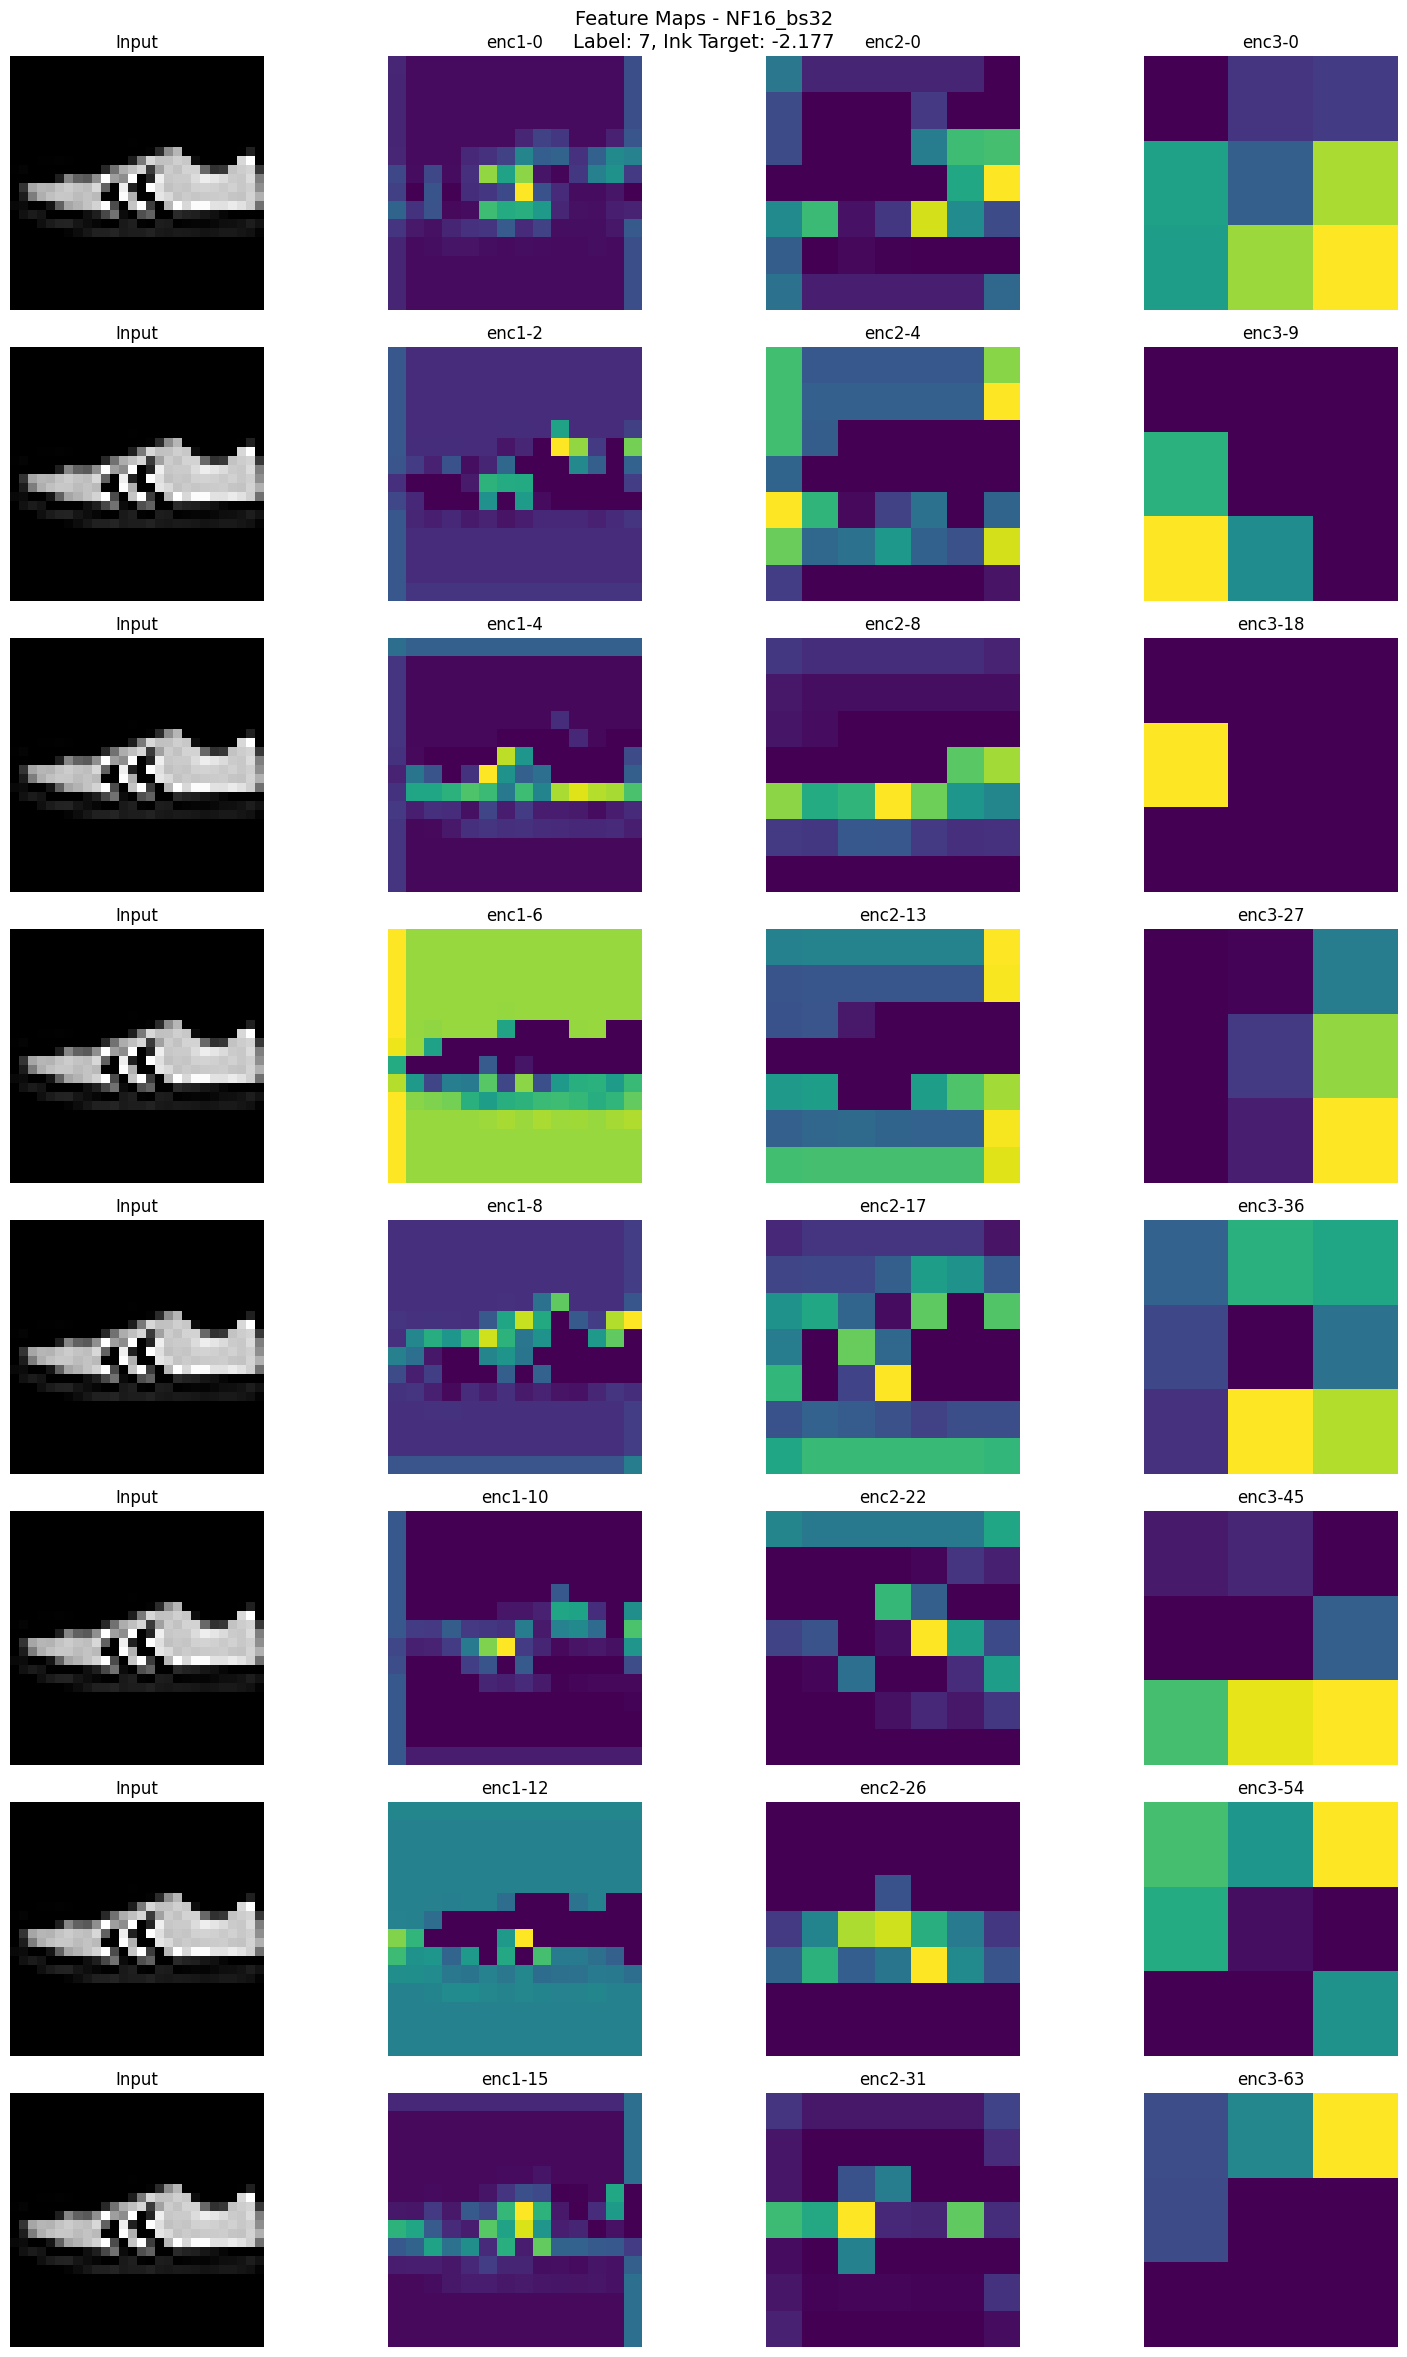


------------------------------------------------------------------------------------------------------------------------------------------------------



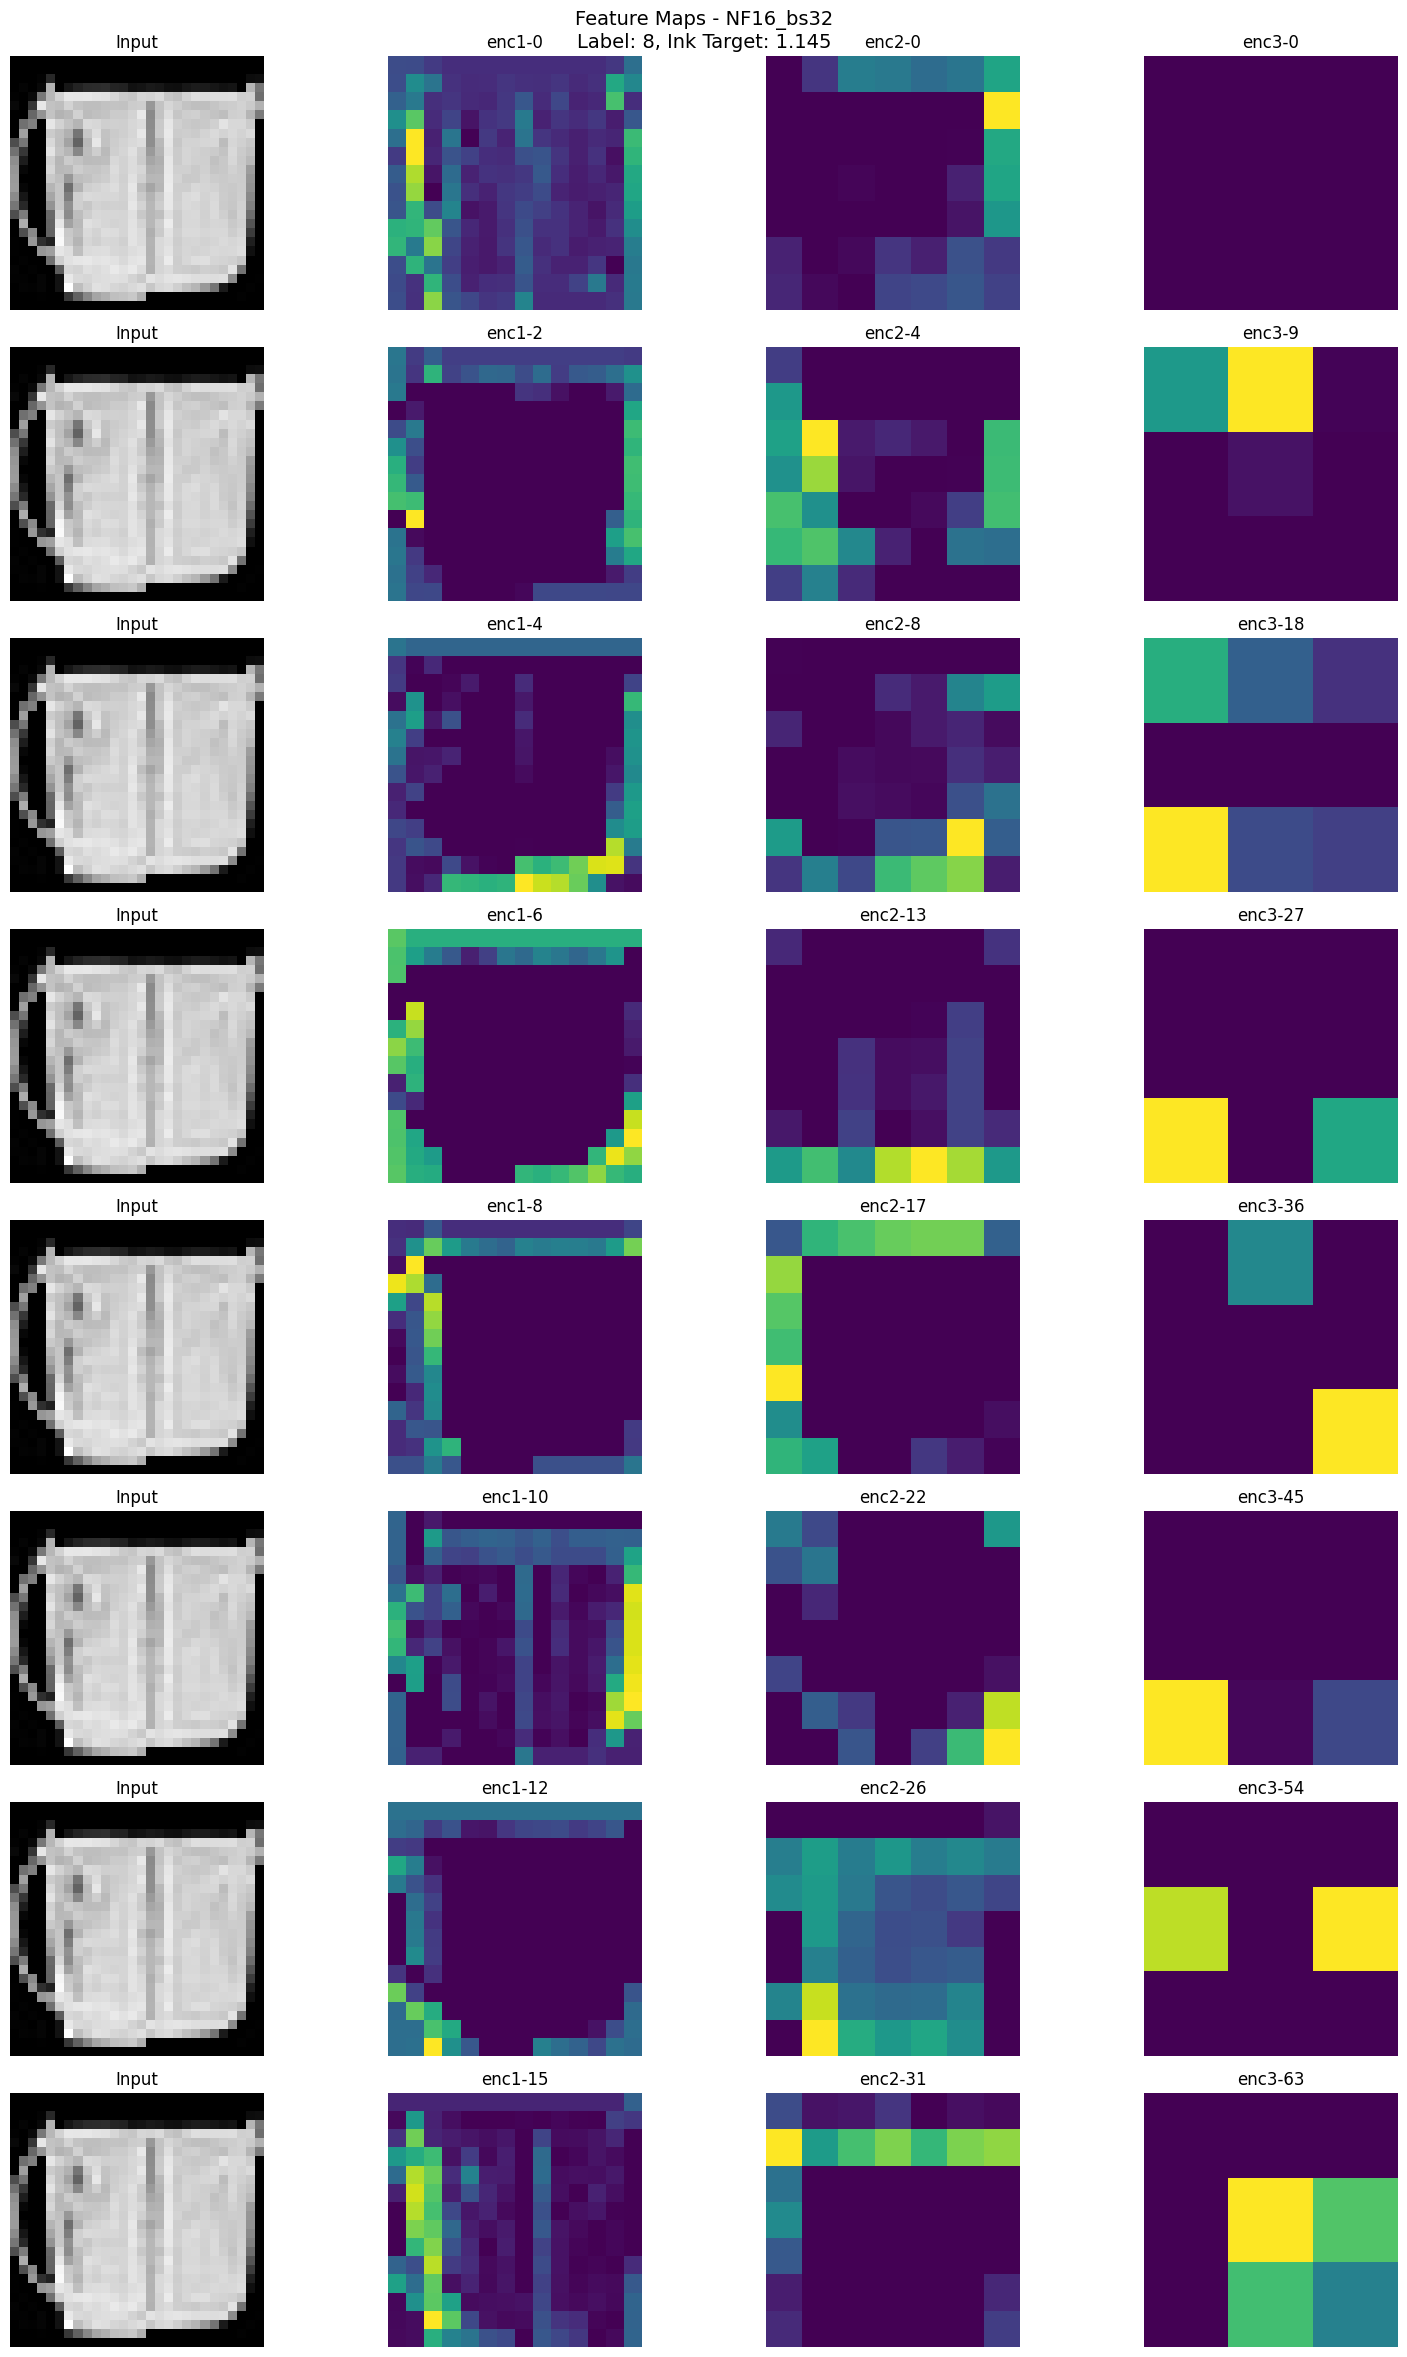


------------------------------------------------------------------------------------------------------------------------------------------------------



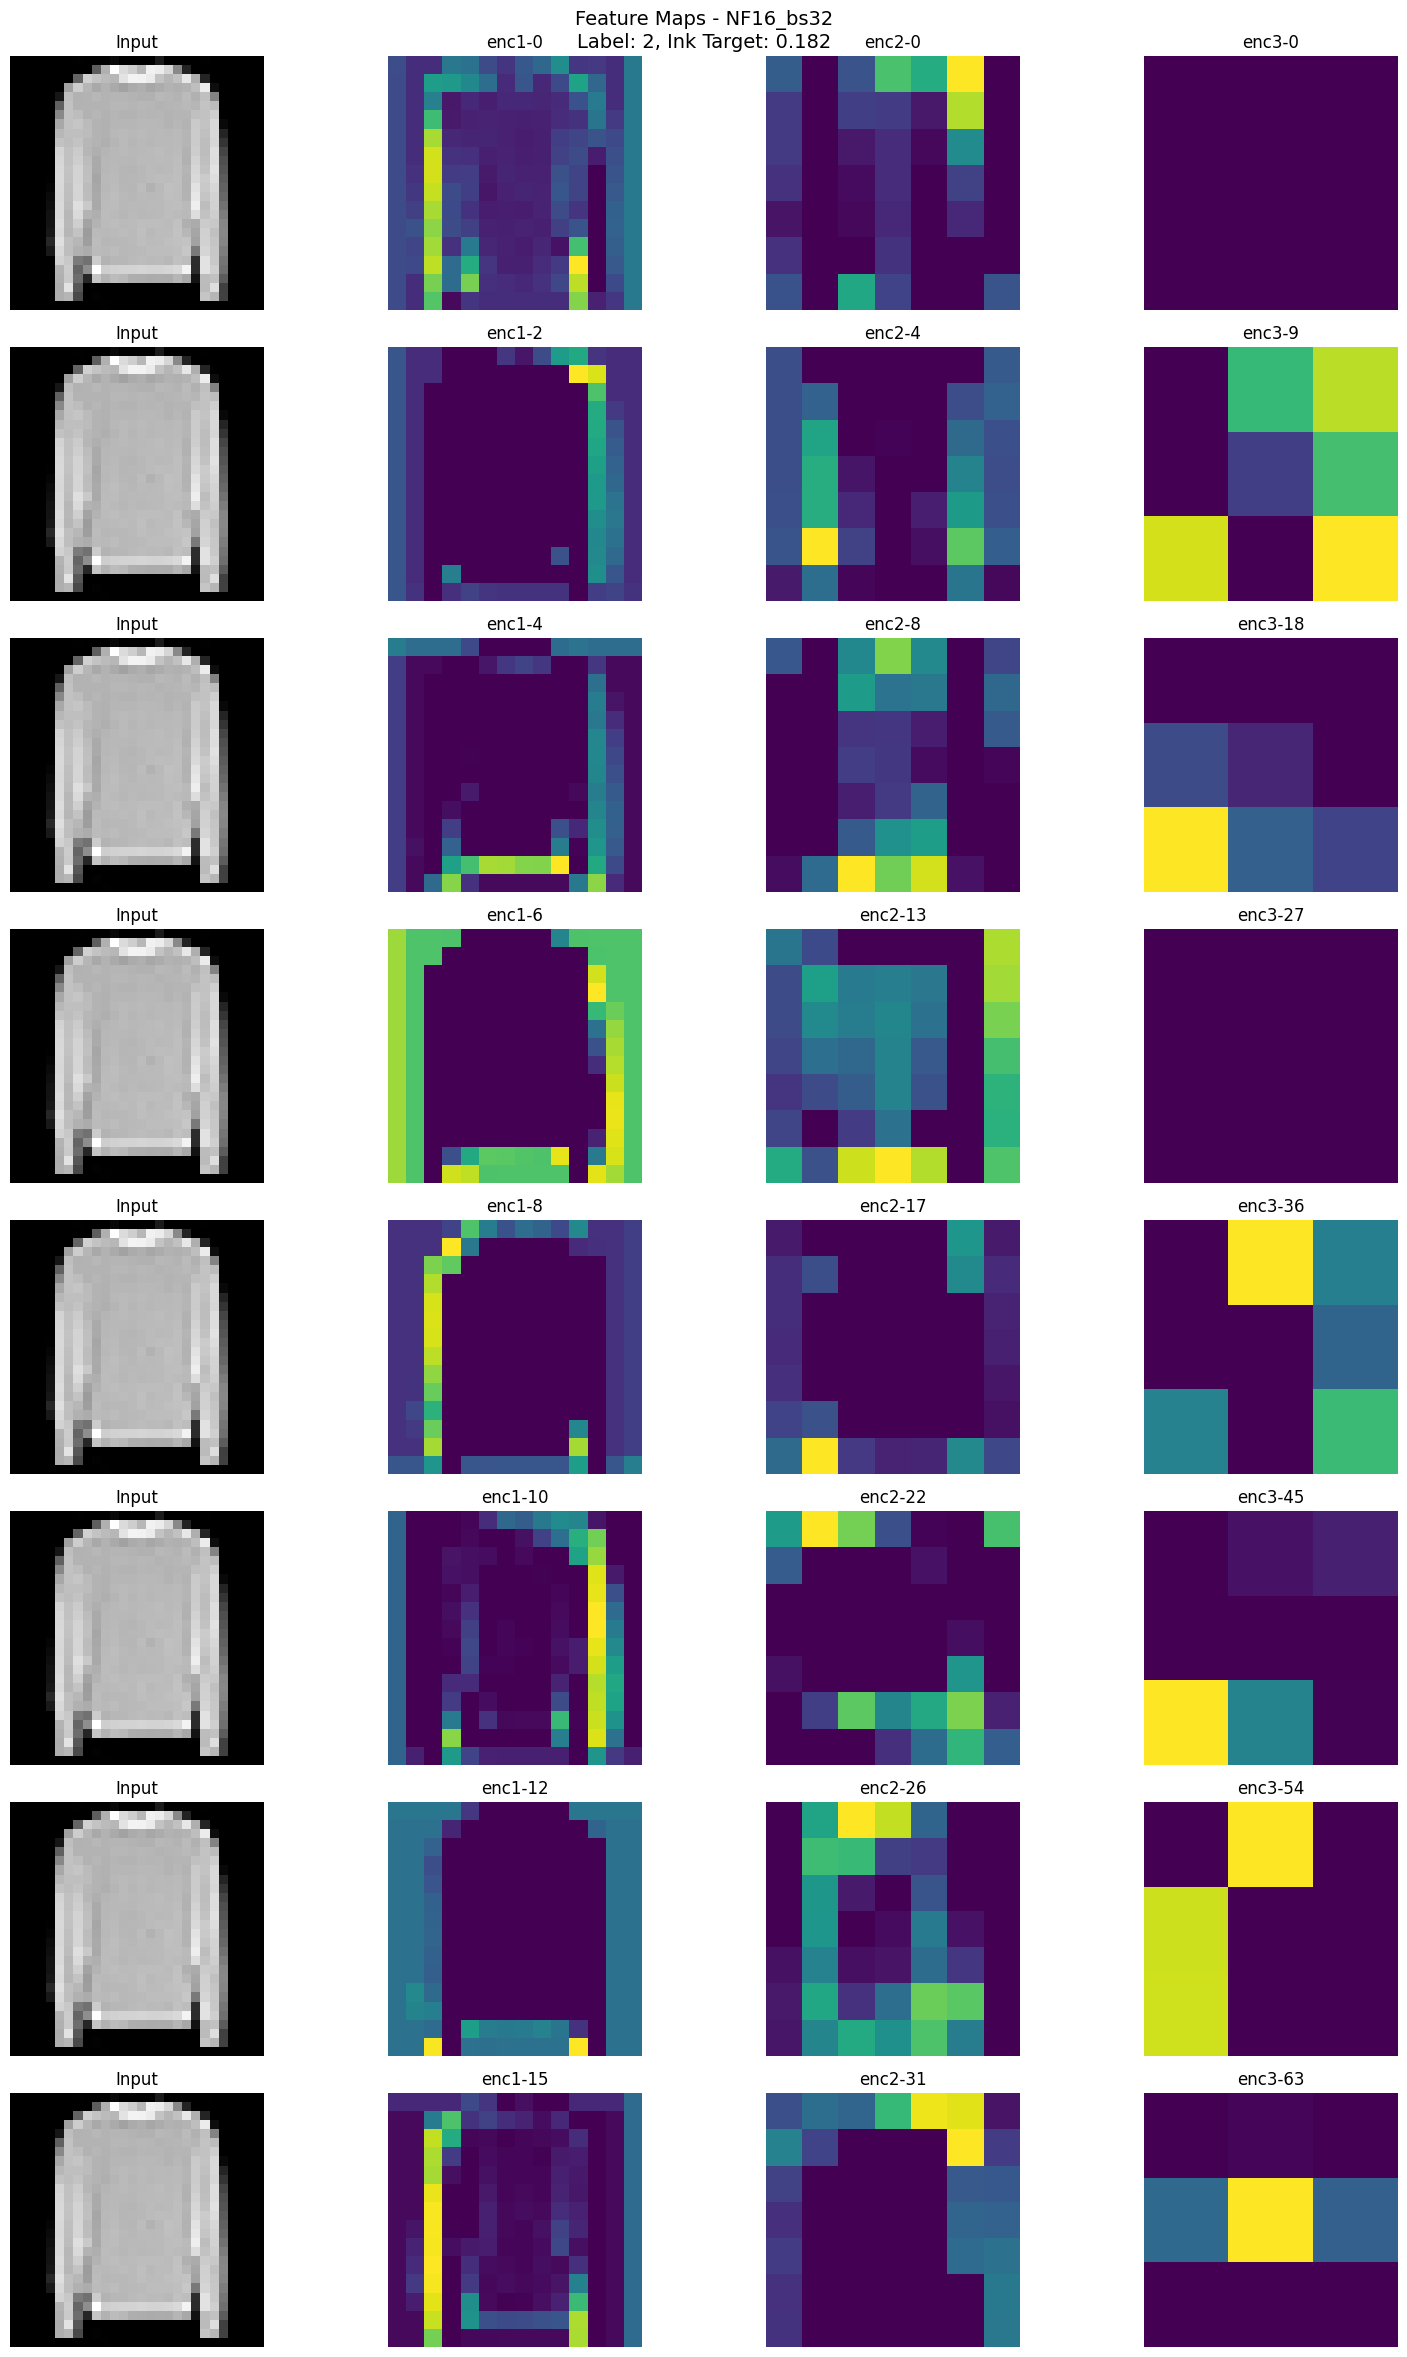


------------------------------------------------------------------------------------------------------------------------------------------------------



In [20]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_feature_maps(architecture_models[0],test_loader,device,"NF16_bs32",
                       num_images=3,num_features=8)

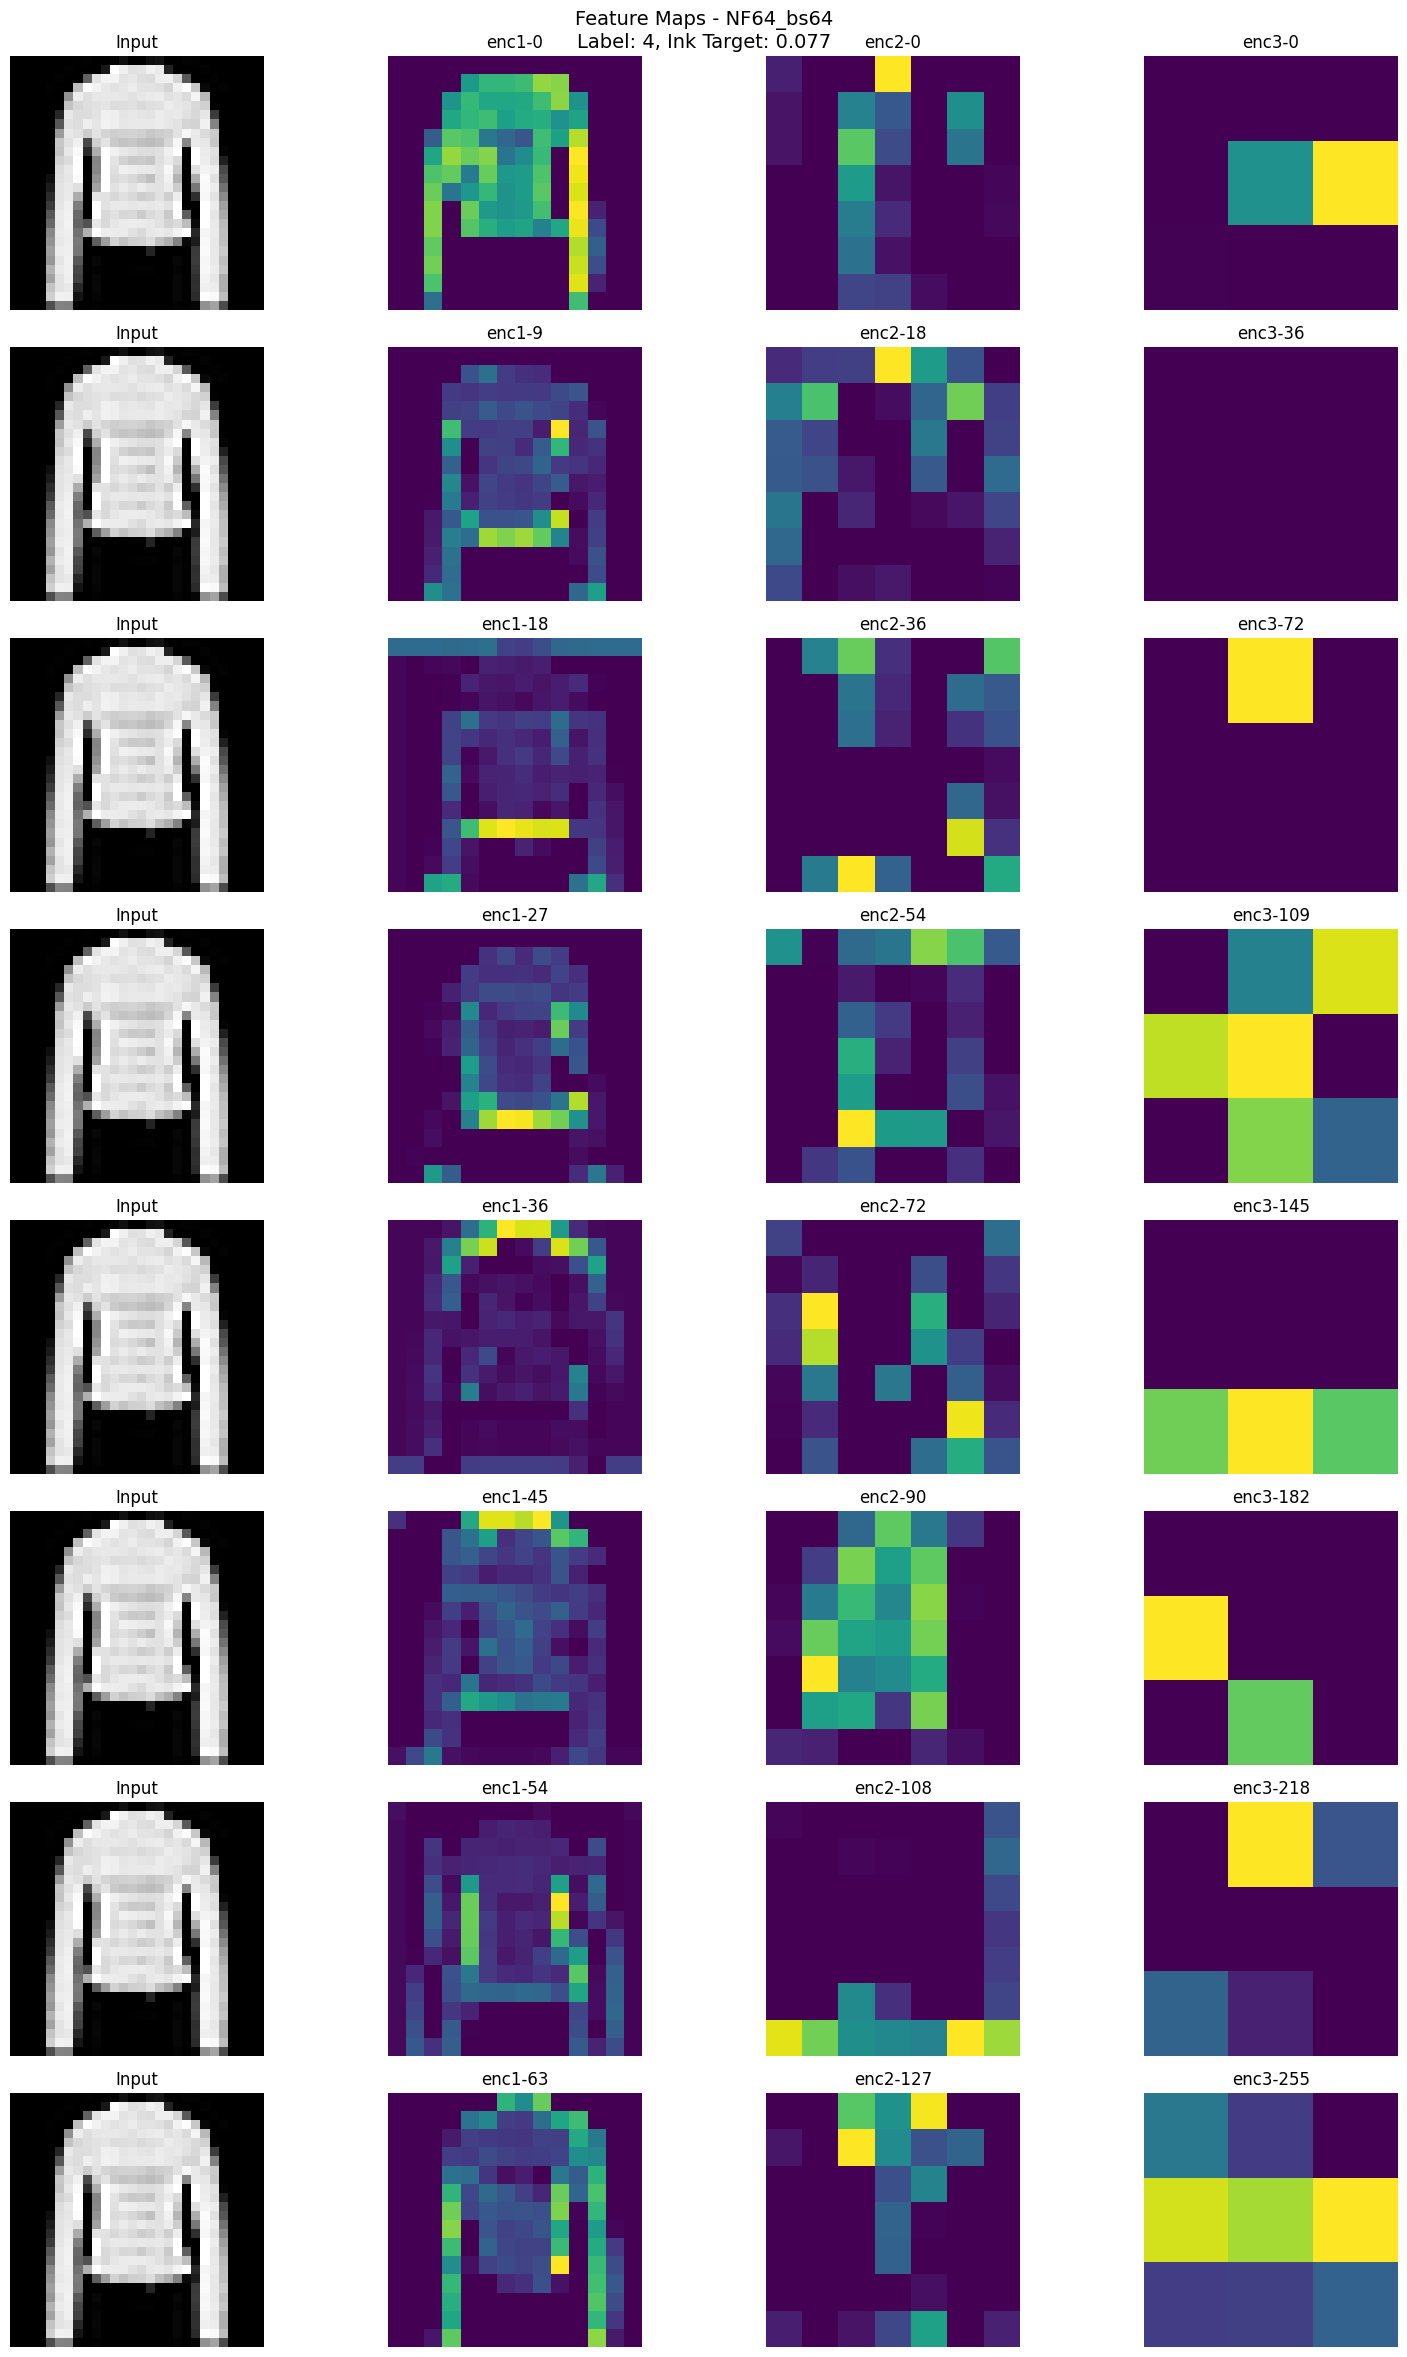


------------------------------------------------------------------------------------------------------------------------------------------------------



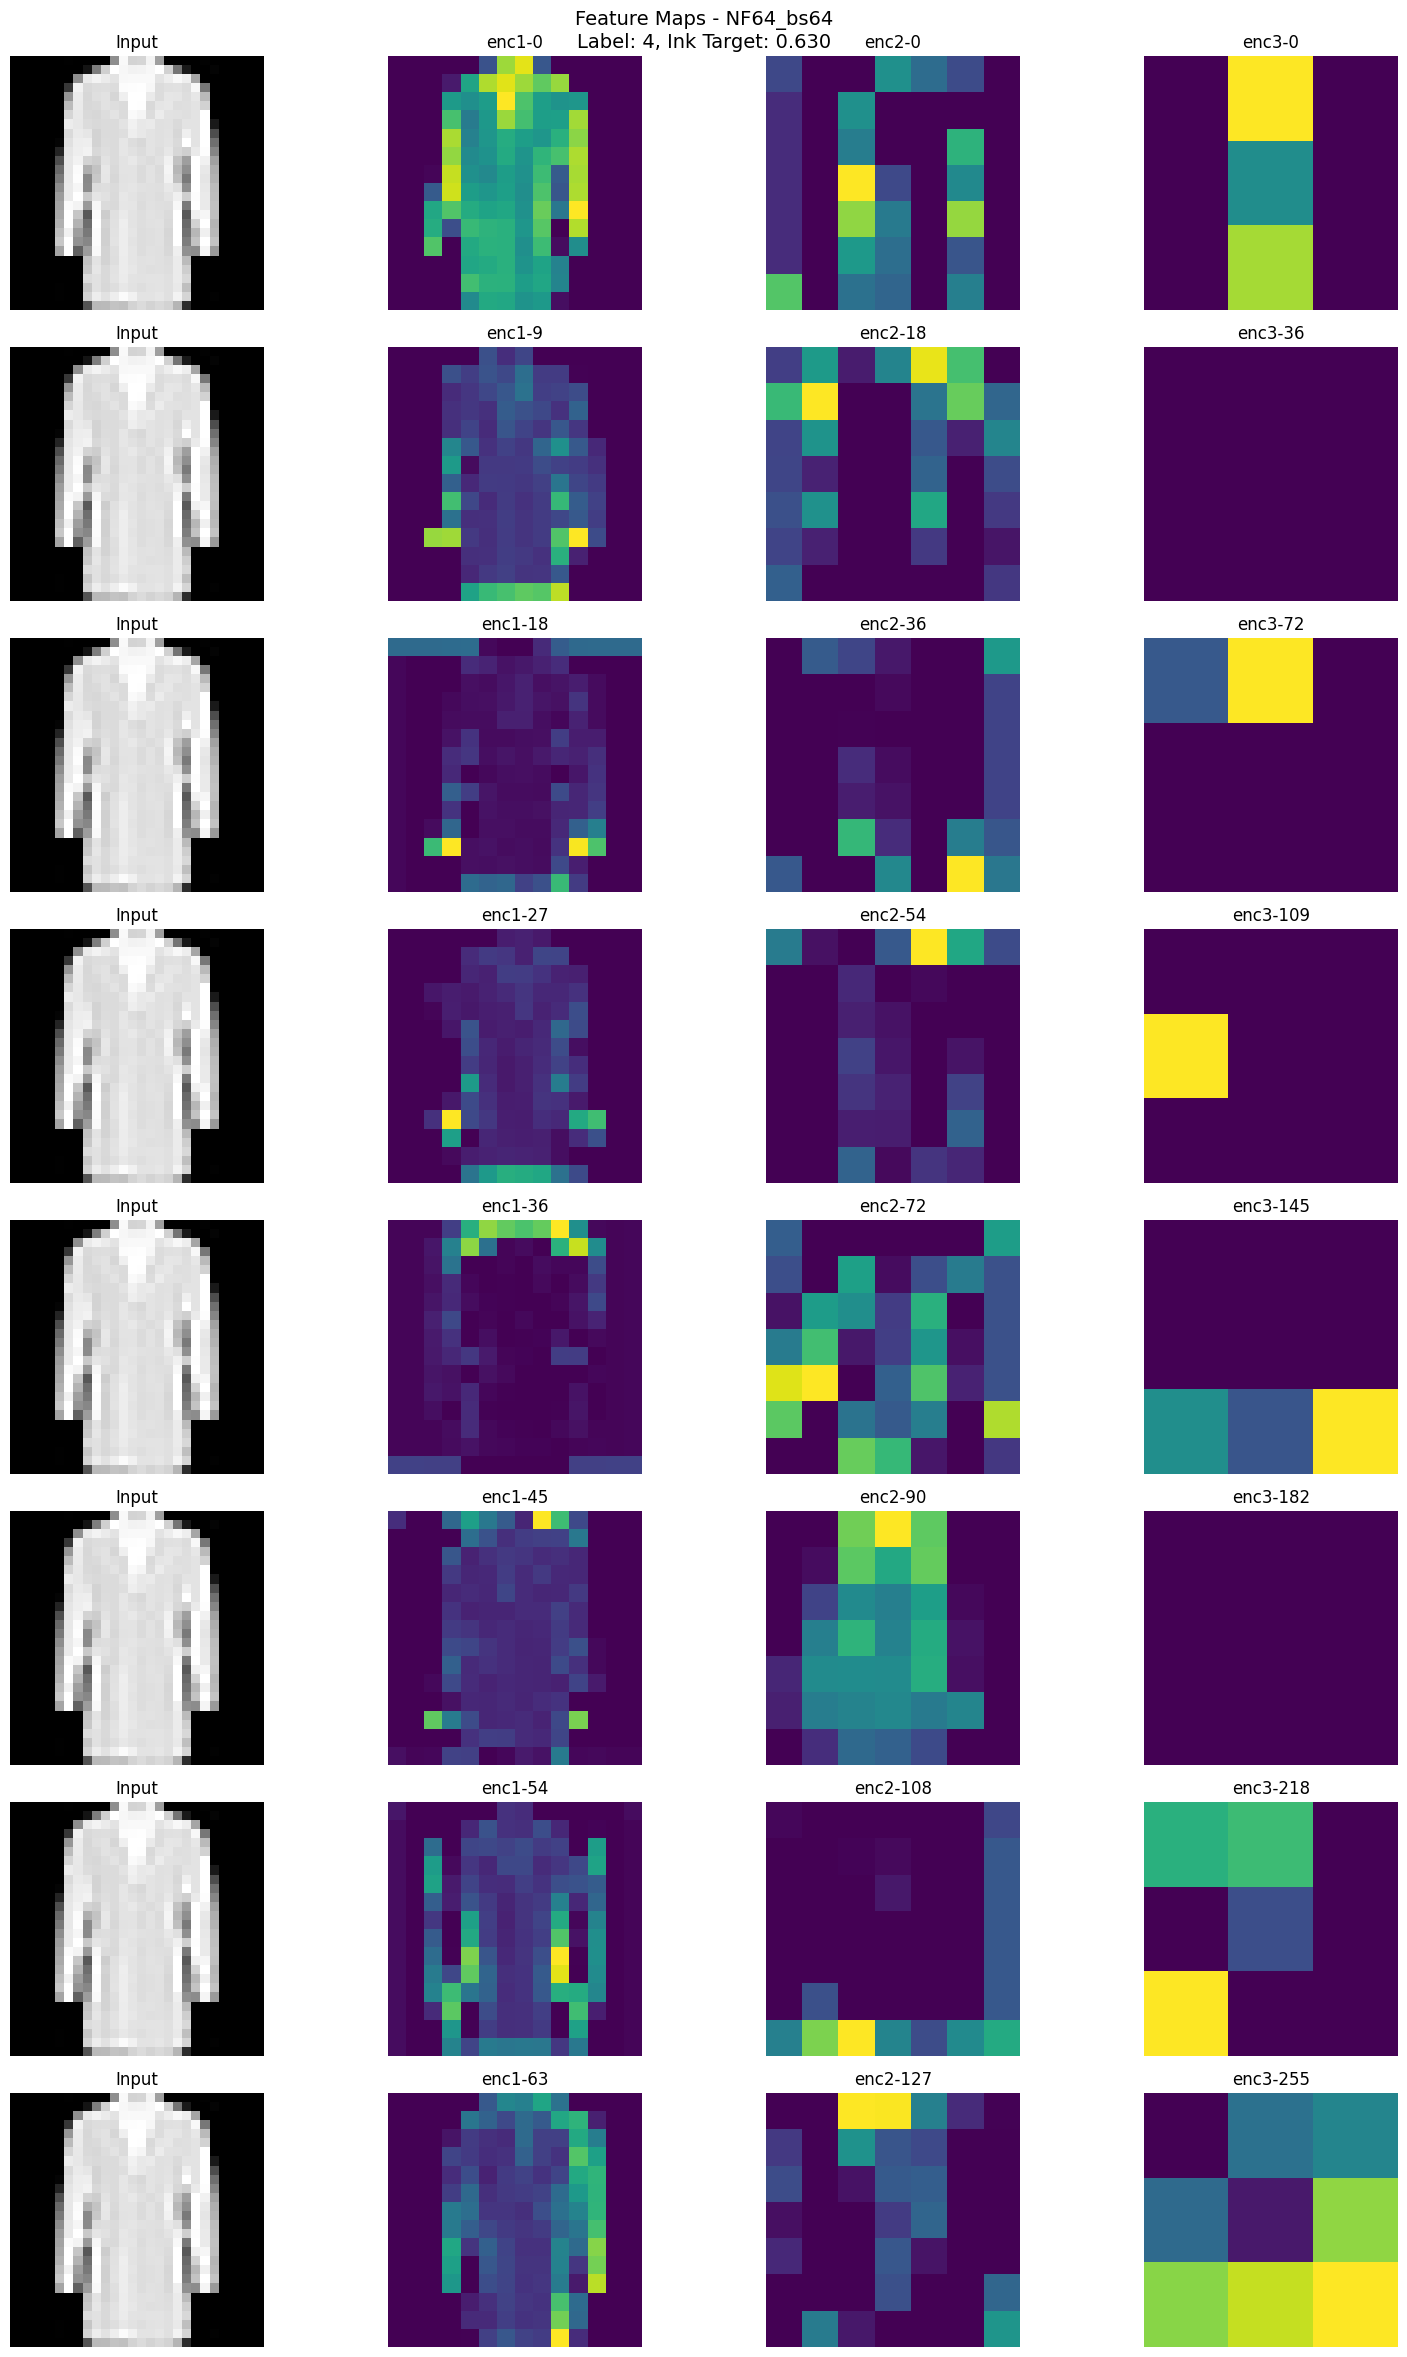


------------------------------------------------------------------------------------------------------------------------------------------------------



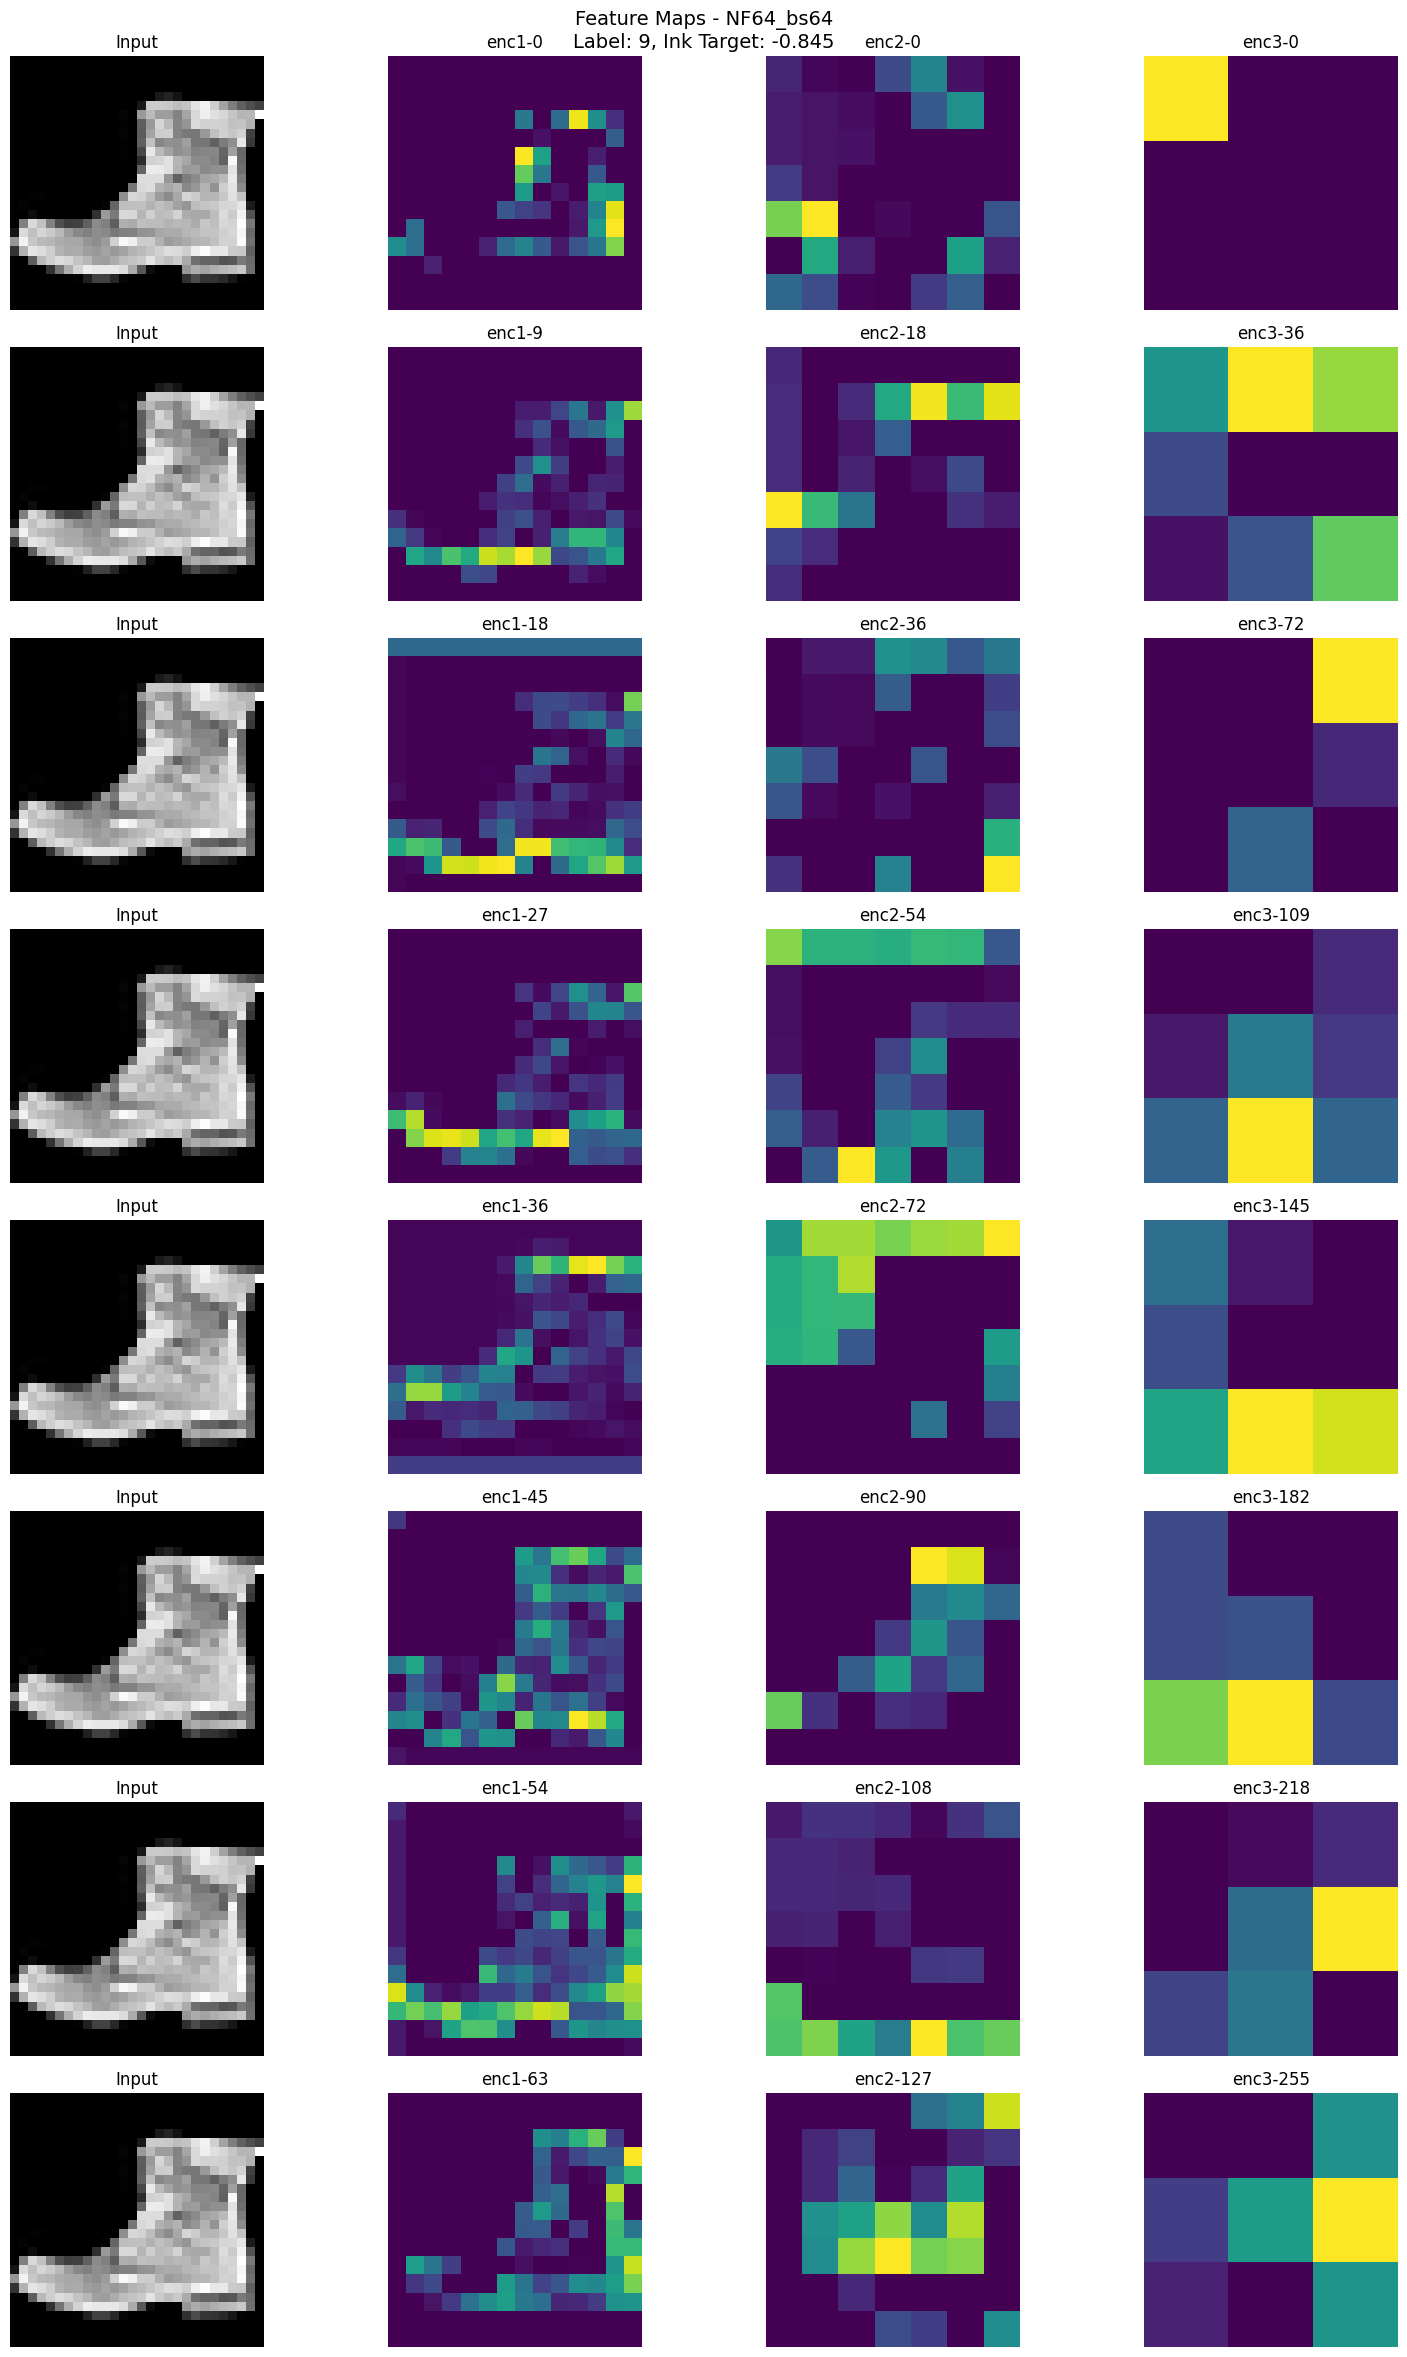


------------------------------------------------------------------------------------------------------------------------------------------------------



In [21]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_feature_maps(architecture_models[1],test_loader,device,"NF64_bs64",
                       num_images=3,num_features=8)

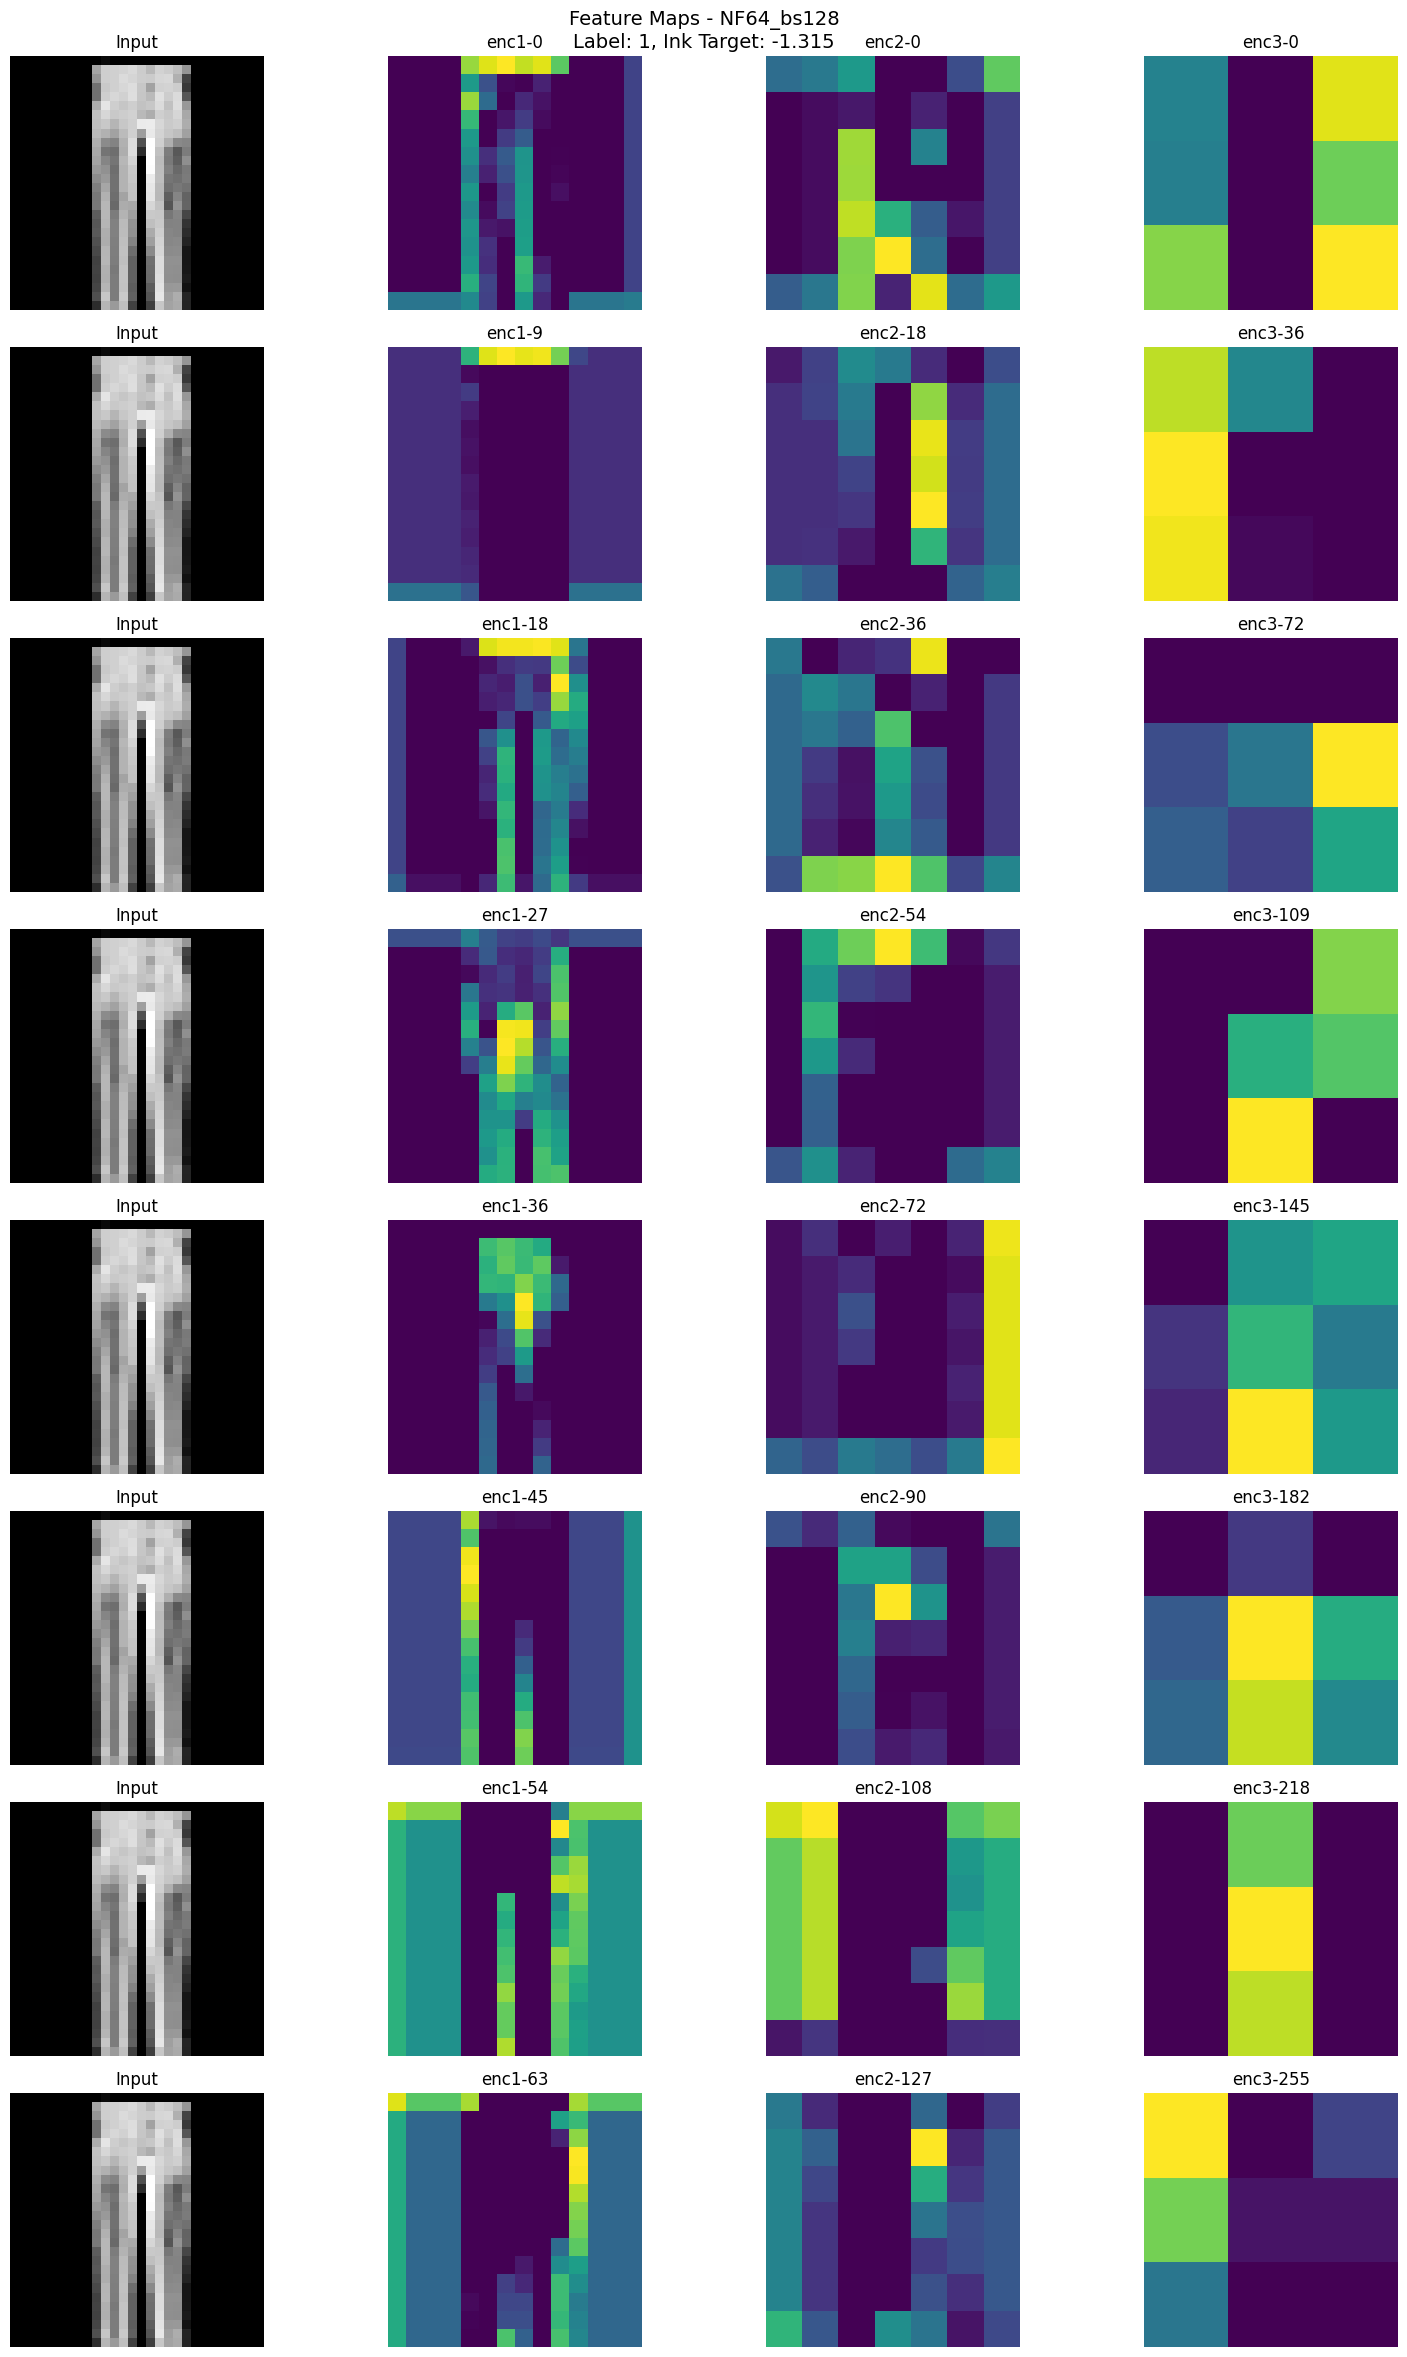


------------------------------------------------------------------------------------------------------------------------------------------------------



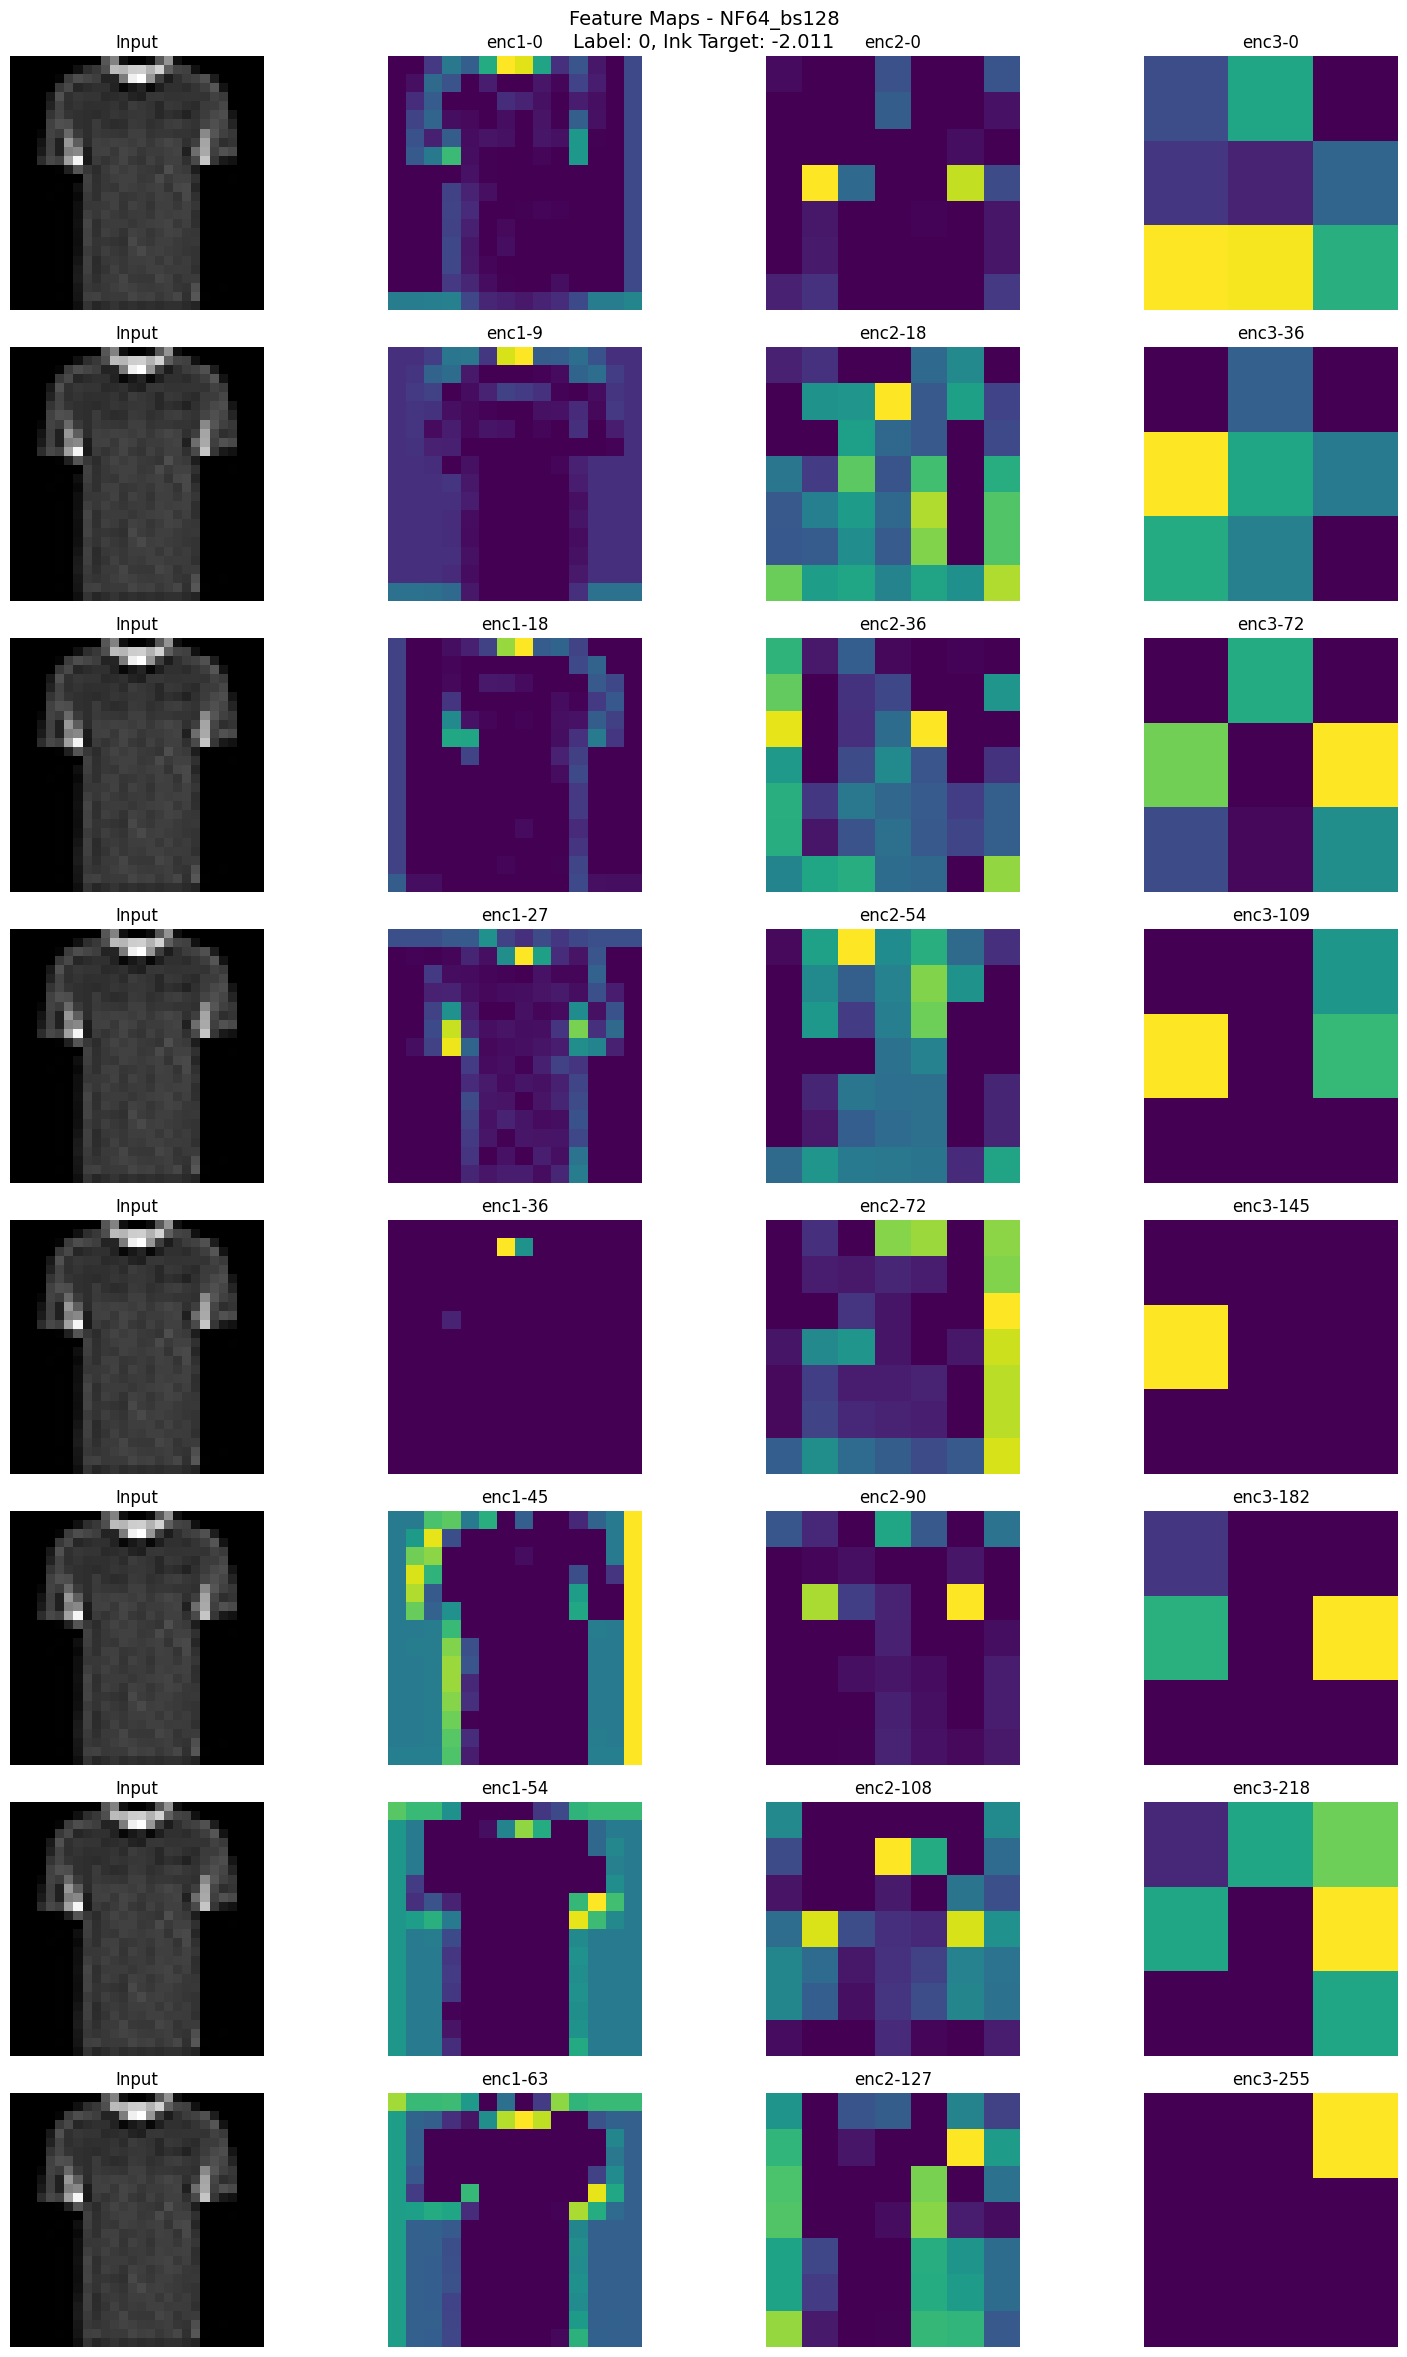


------------------------------------------------------------------------------------------------------------------------------------------------------



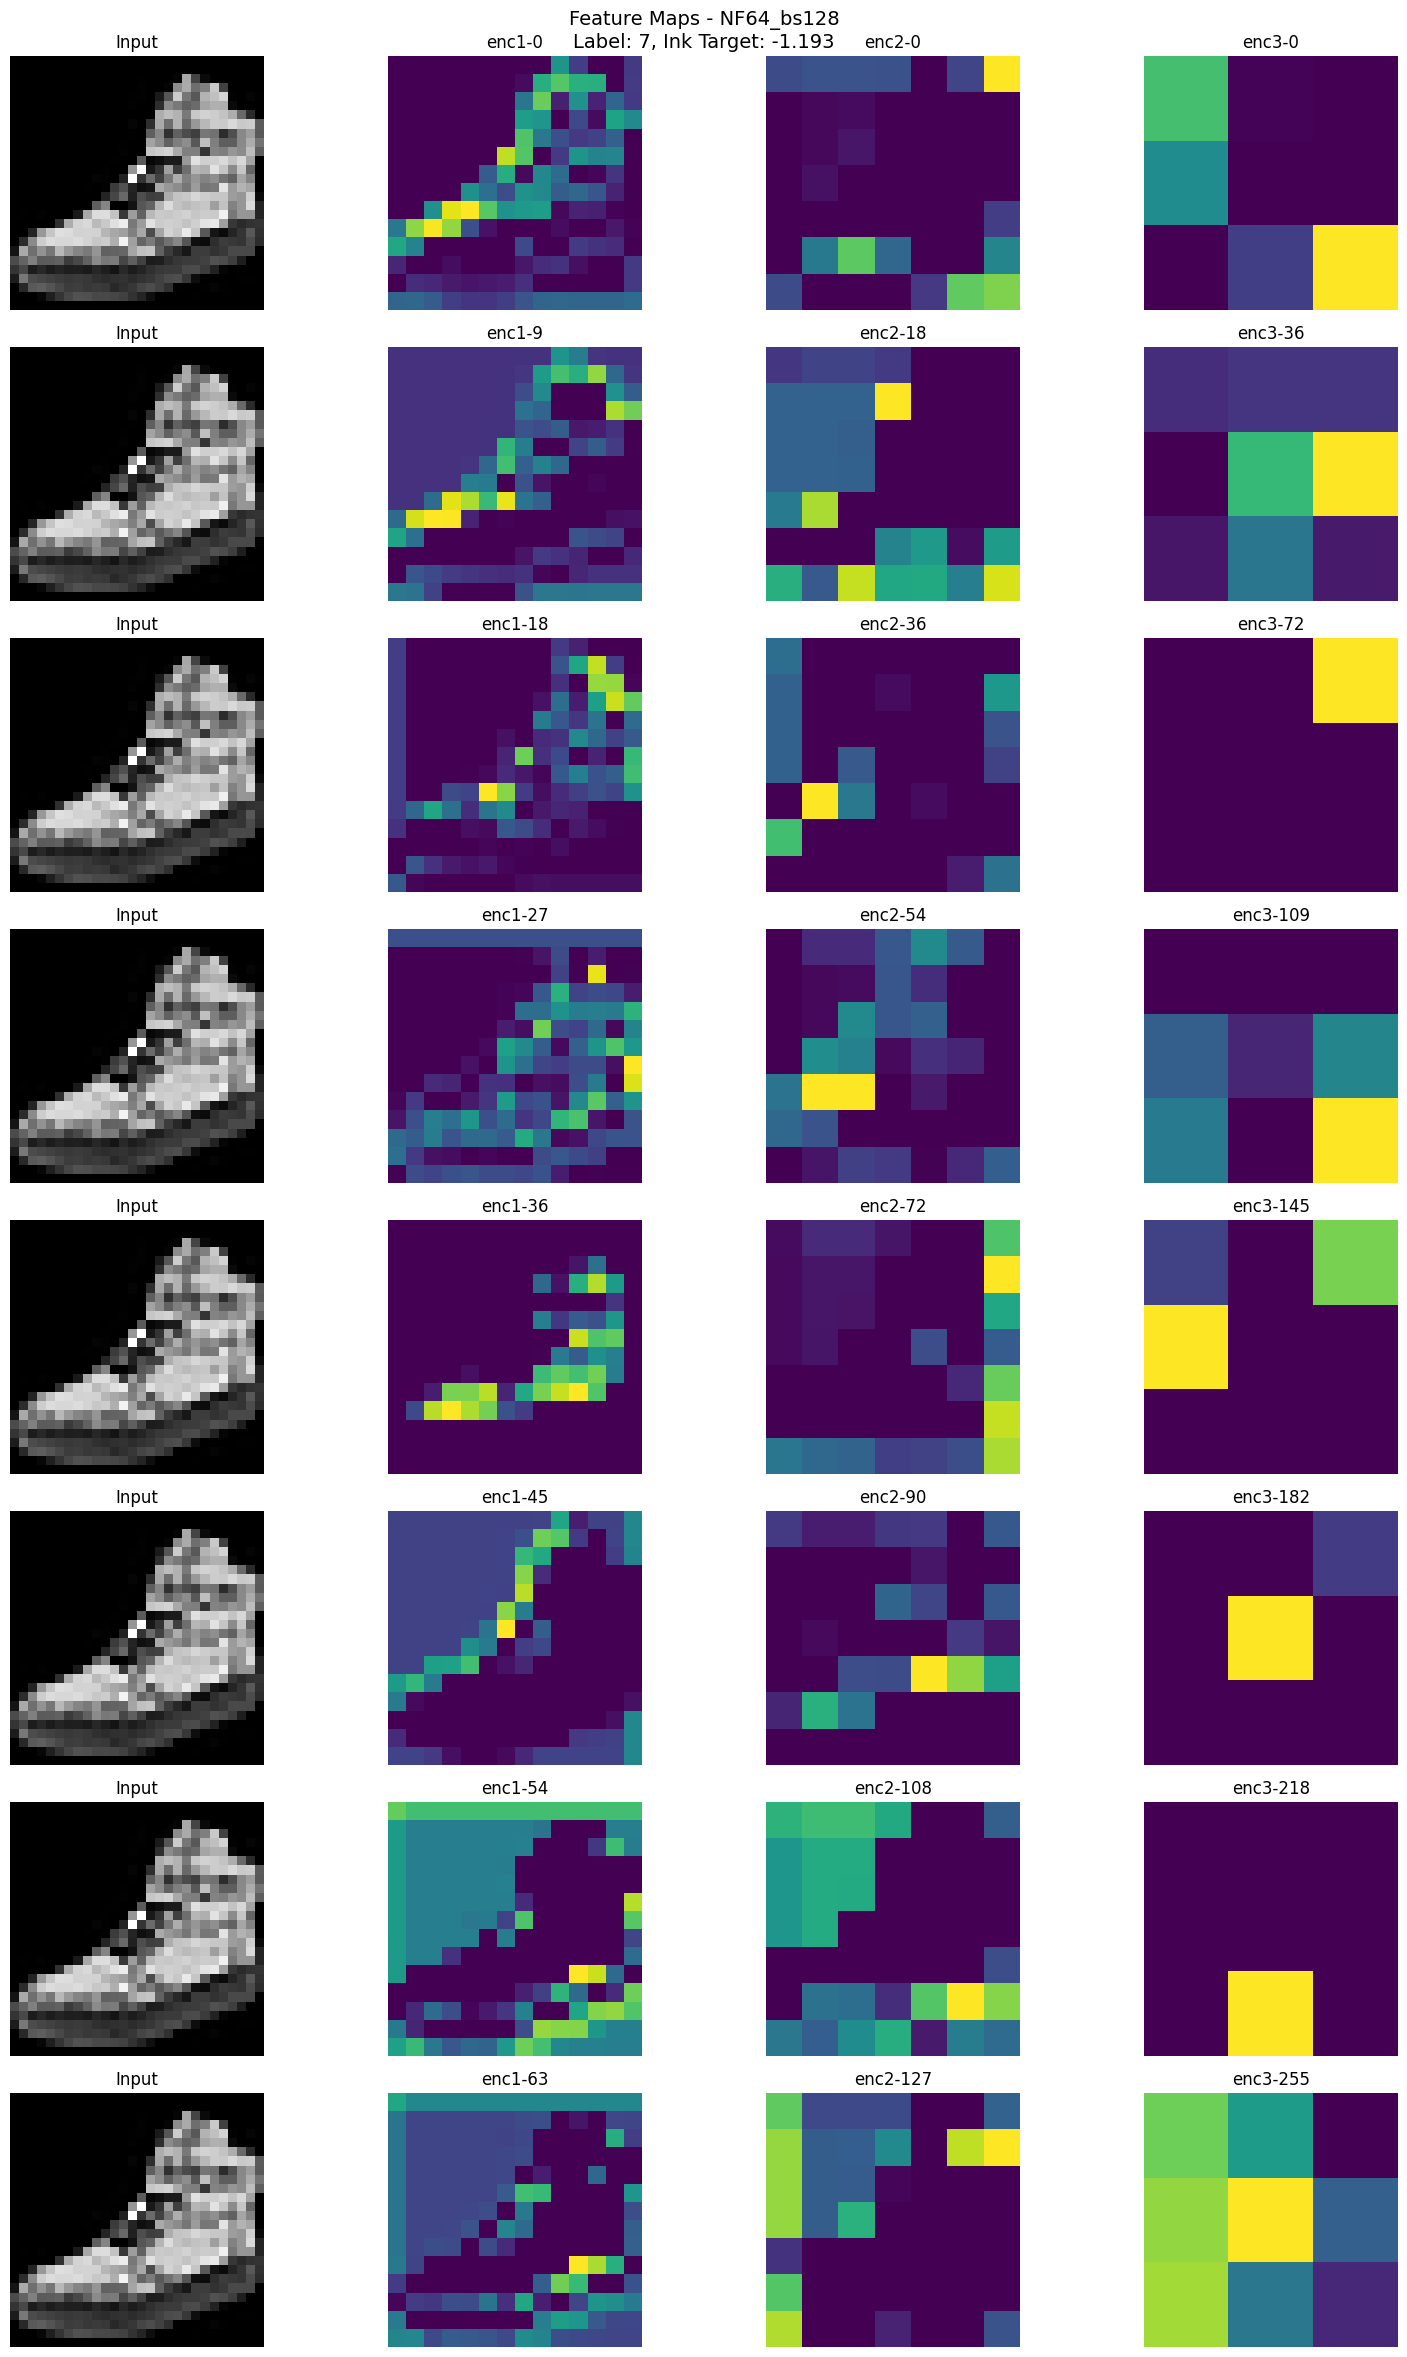


------------------------------------------------------------------------------------------------------------------------------------------------------



In [22]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_feature_maps(architecture_models[2],test_loader,device,"NF64_bs128",
                       num_images=3,num_features=8)

In [ ]:
best_accuracy_config = {
    "run_name": "best_accuracy_model",
    "lambda1": 2.0, "lambda2": 1.0,
    "lr": 1e-3, "dropout_rate": 0.2, "NF": 64, "batch_size": 64,
    "epochs": num_epochs, "optimizer": "AdamW",
    "group": "Best Models"
}

less_rmse_config = {
    "run_name": "less_rmse_model",
    "lambda1": 1.0, "lambda2": 2.0,
    "lr": 1e-3, "dropout_rate": 0.3, "NF": 64, "batch_size": 128,
    "epochs": num_epochs, "optimizer": "AdamW",
    "group": "Best Models"
}


In [ ]:
best_acc_model=train_and_log(best_accuracy_config)

Epoch 20/20: 100%|██████████| 844/844 [00:30<00:00, 27.96it/s]


Run finished for config {'run_name': 'best_accuracy_model', 'lambda1': 2, 'lambda2': 1, 'lr': 0.001, 'dropout_rate': 0.2, 'NF': 64, 'batch_size': 64, 'epochs': 20, 'optimizer': 'AdamW', 'group': 'Best Models'} , val_acc=0.9293,rmse=0.0918


Train Accuracy,▁▄▅▆▆▆▇▇▇▇▇▇▇███████
Train CE Loss,█▅▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁
Train MSE Loss,█▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁
Validation Accuracy,▁▃▅▅▅▆▆▆▆▇▇▇▇▇█▇▇███
Validation CE Loss,█▆▄▄▄▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁
Validation MAE,▇▁▅▂▂▁▁▅▂▃▁▁█▁▃▁▂▂▂▂
Validation MSE Loss,█▁▄▂▂▁▁▃▂▃▁▁▆▁▂▁▂▁▁▂
Validation RMSE,█▁▅▂▂▁▁▄▂▃▁▁▇▁▃▂▂▂▁▂
Validation Total Loss,█▆▄▄▄▃▃▂▂▂▂▂▂▂▂▂▂▁▁▁
+1,...


In [ ]:
less_rmse_model=train_and_log(less_rmse_config)

Epoch 20/20: 100%|██████████| 422/422 [00:28<00:00, 14.73it/s]


Run finished for config {'run_name': 'less_rmse_model', 'lambda1': 1, 'lambda2': 2, 'lr': 0.001, 'dropout_rate': 0.3, 'NF': 64, 'batch_size': 128, 'epochs': 20, 'optimizer': 'AdamW', 'group': 'Best Models'} , val_acc=0.9210,rmse=0.0546


Train Accuracy,▁▅▆▆▆▇▇▇▇▇▇▇████████
Train CE Loss,█▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁
Train MSE Loss,█▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁
Train Total Loss,█▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
Validation Accuracy,▁▃▅▄▅▅▆▆▆▆▇▇▇▇██▇███
Validation CE Loss,█▆▄▄▄▃▃▃▂▂▂▂▁▂▁▁▂▁▁▁
Validation MAE,▂▄▂▆▆▂▁█▃▃▂▄▁▂▂▄▁▂▂▁
Validation MSE Loss,▂▃▂▅▅▂▁█▂▂▁▃▁▂▂▃▁▂▂▁
Validation RMSE,▃▄▃▅▆▂▁█▃▃▂▄▁▂▂▄▁▂▂▁
Validation Total Loss,█▆▄▅▅▃▃▄▂▂▂▂▁▂▁▂▂▁▁▁
+1,...


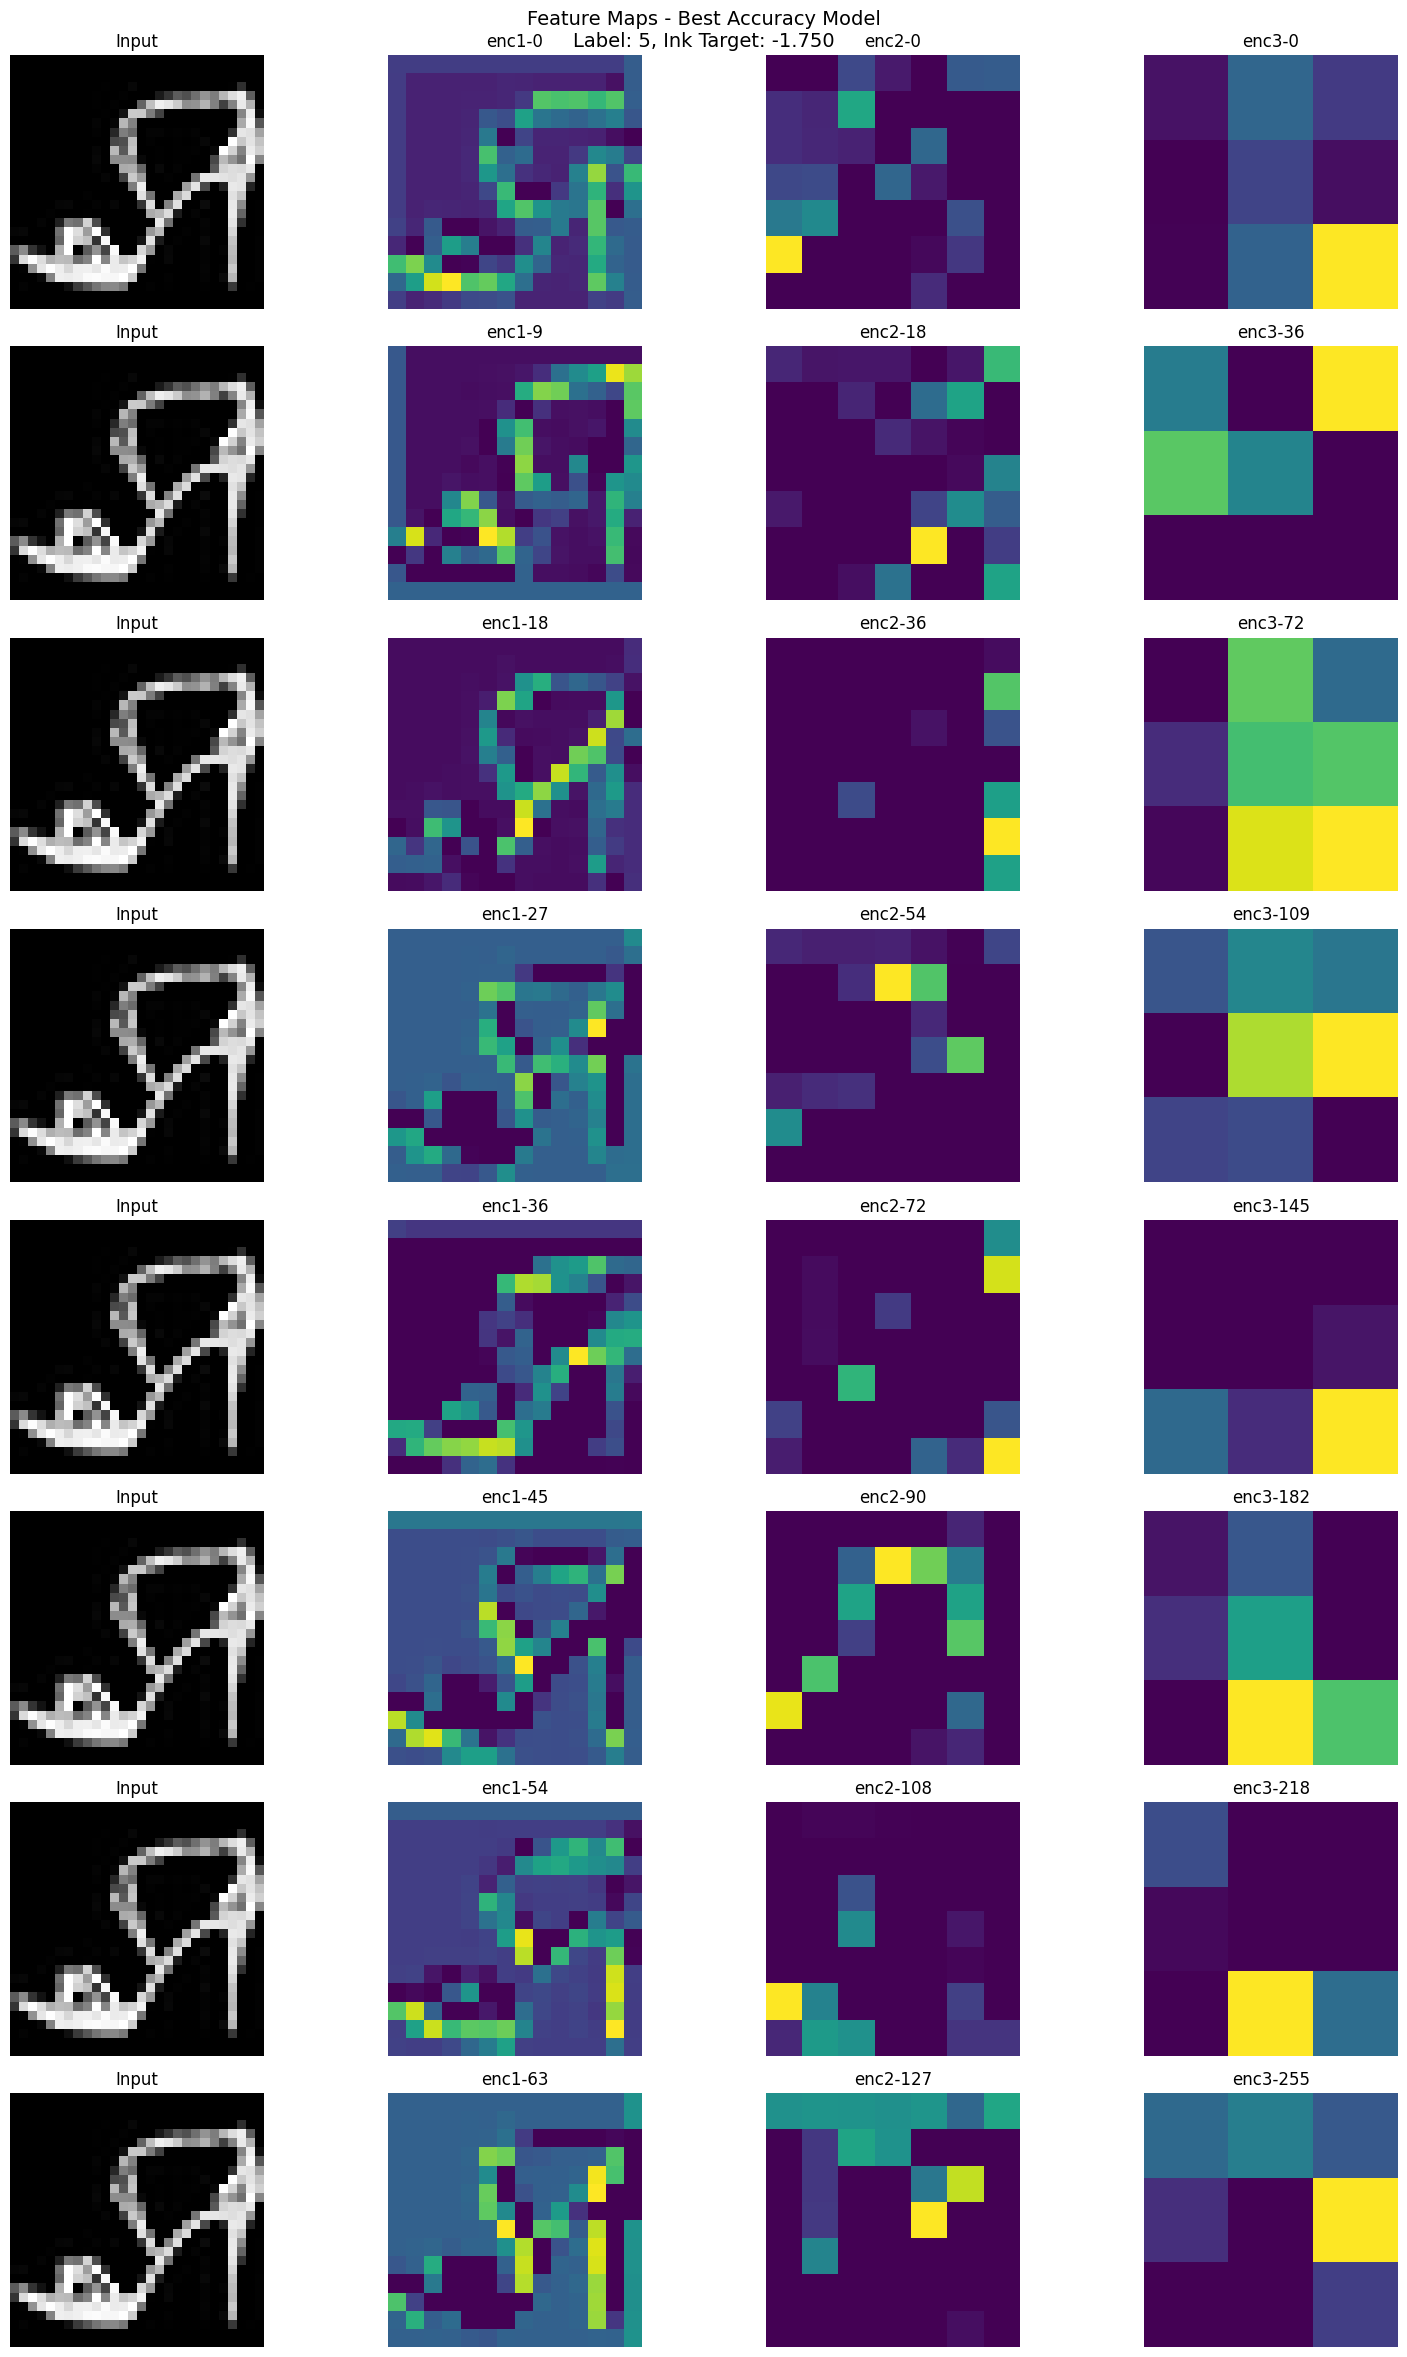


------------------------------------------------------------------------------------------------------------------------------------------------------



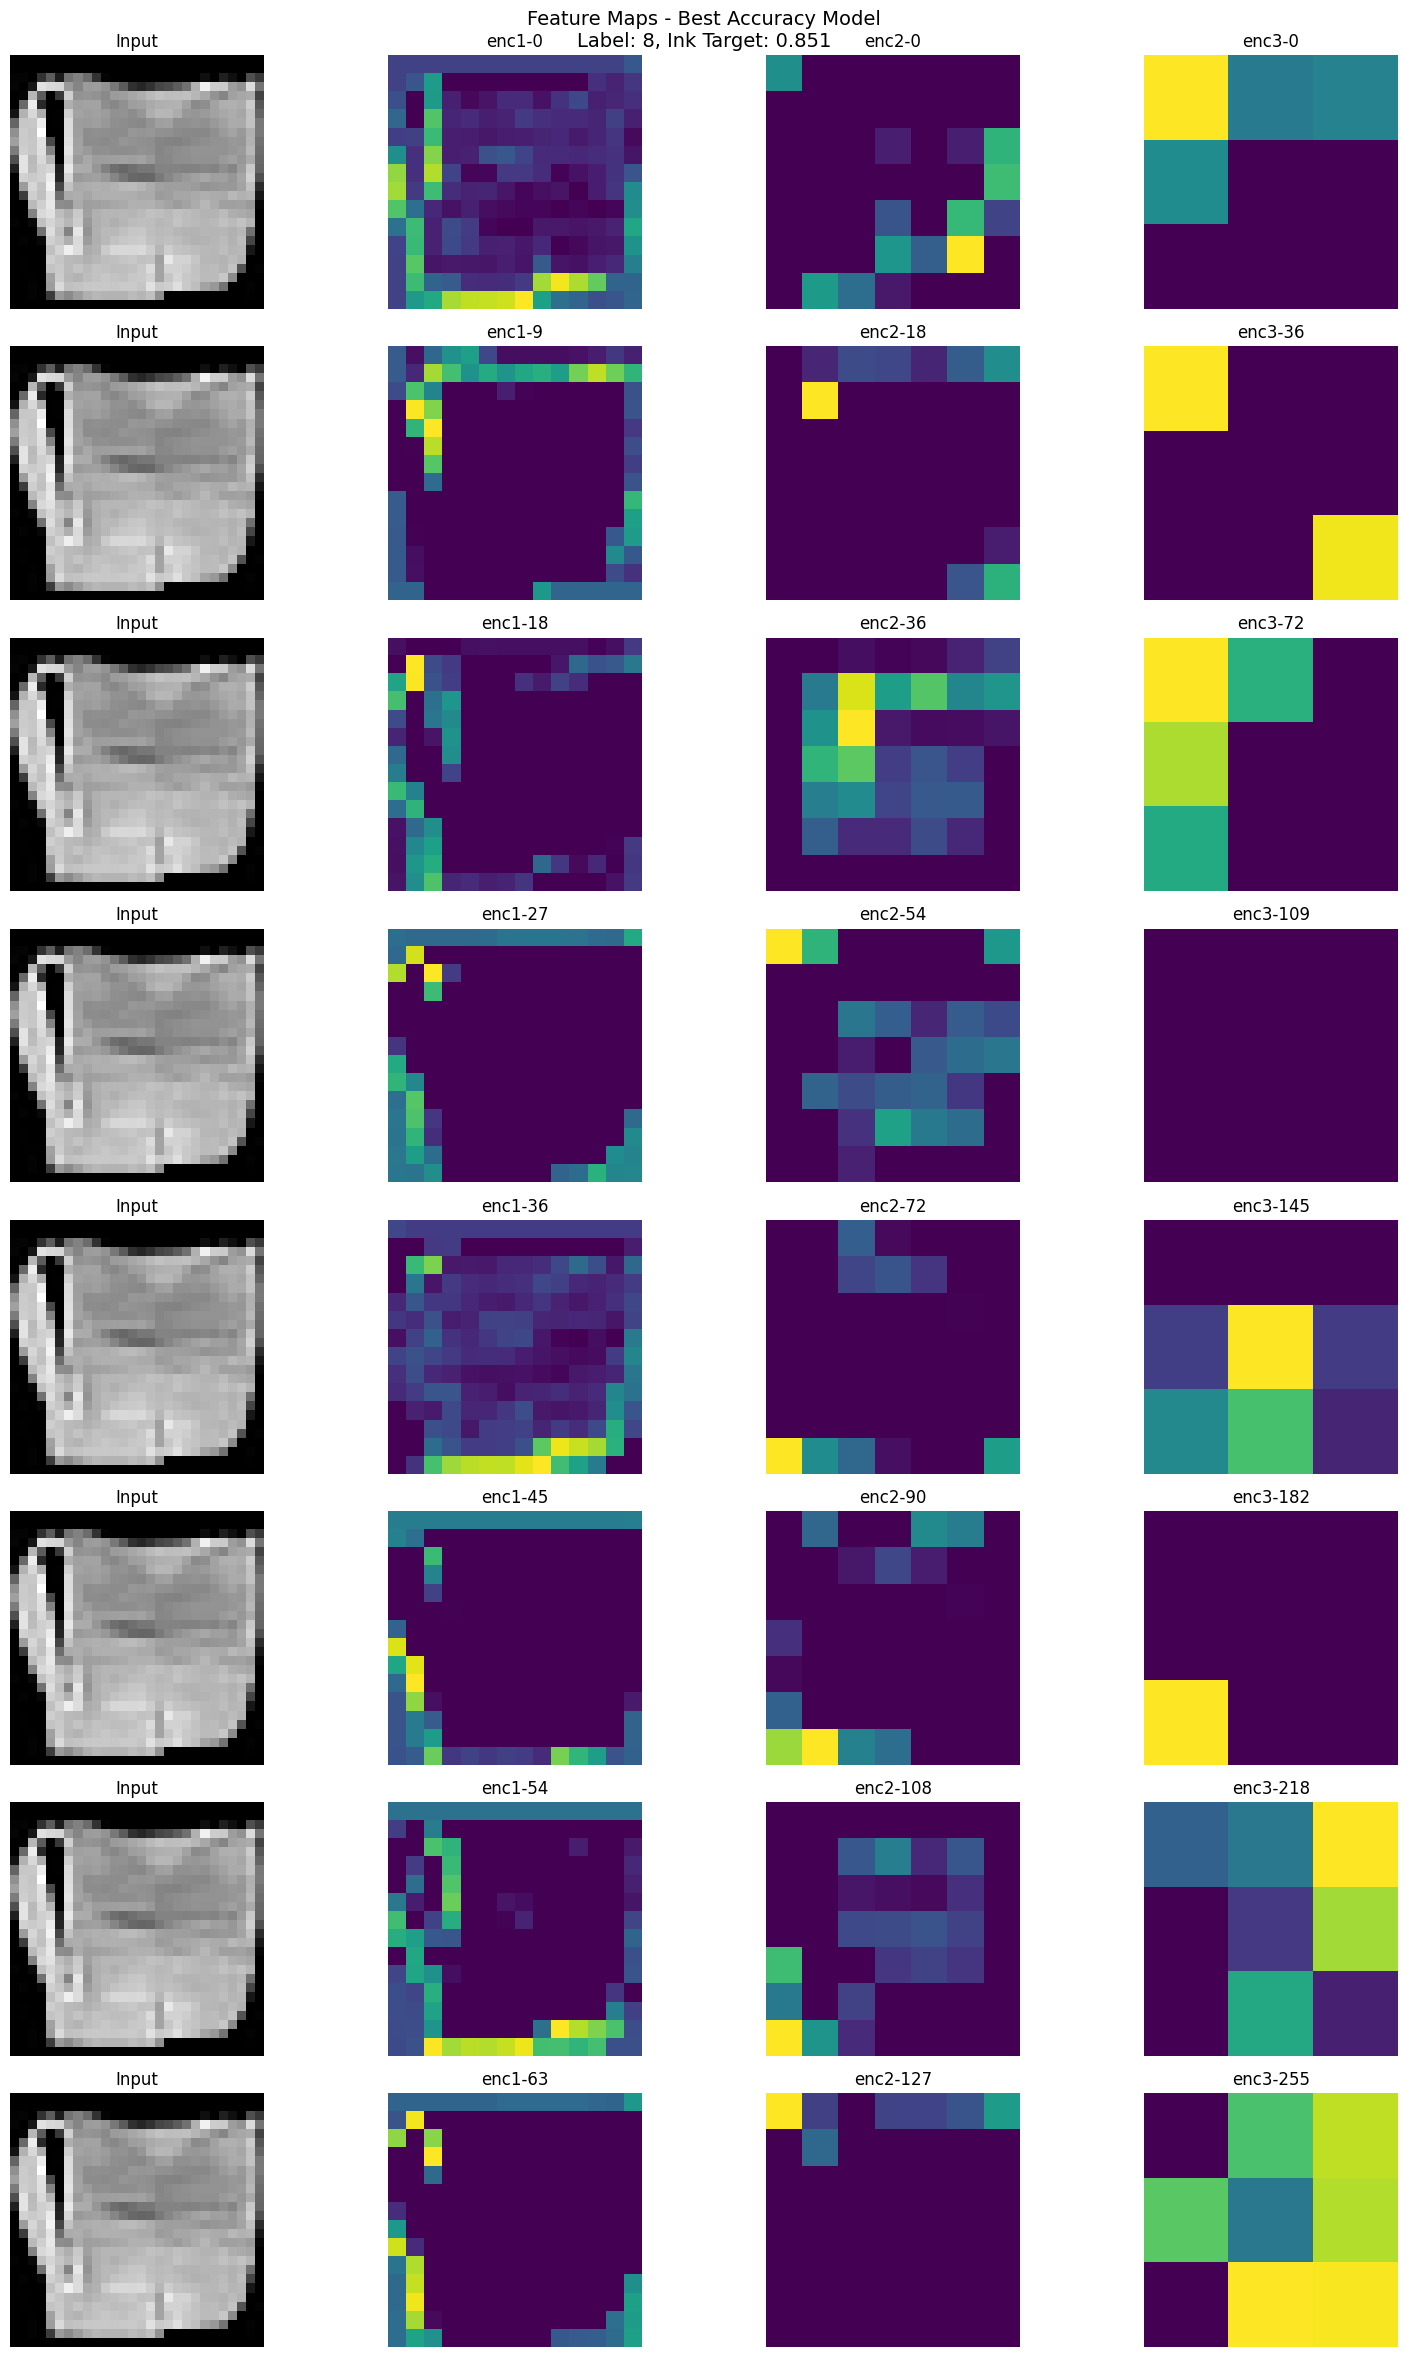


------------------------------------------------------------------------------------------------------------------------------------------------------



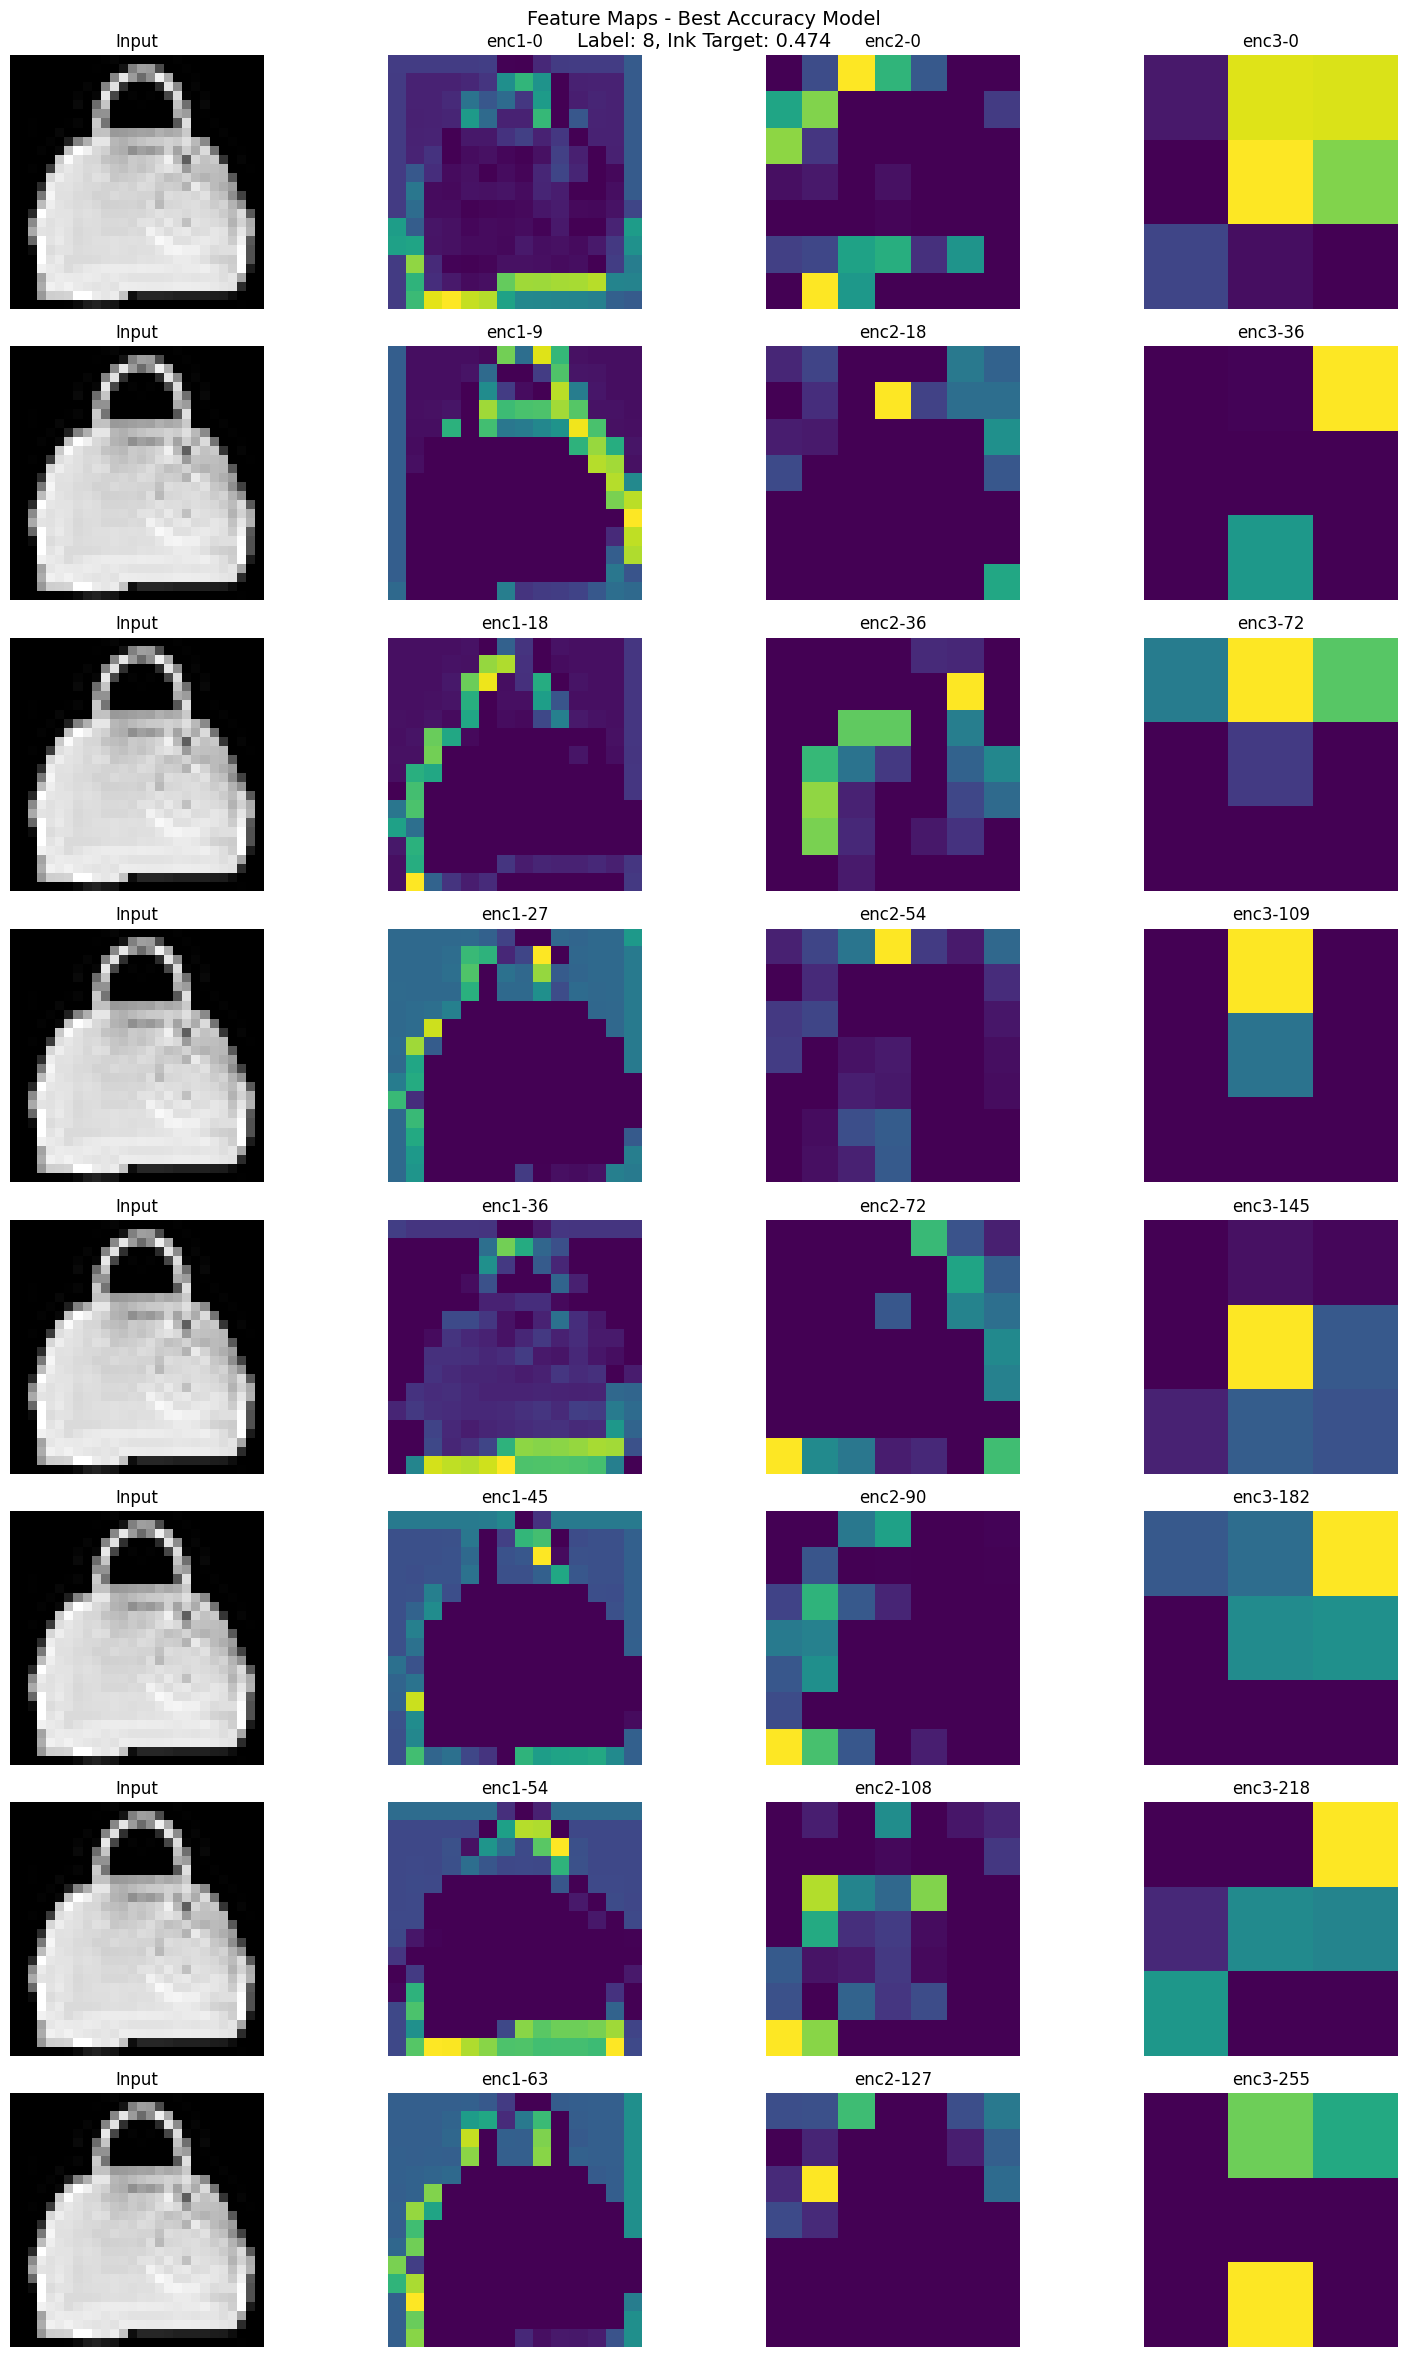


------------------------------------------------------------------------------------------------------------------------------------------------------



In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_feature_maps(best_acc_model,test_loader,device,"Best Accuracy Model",
                       num_images=3,num_features=8)

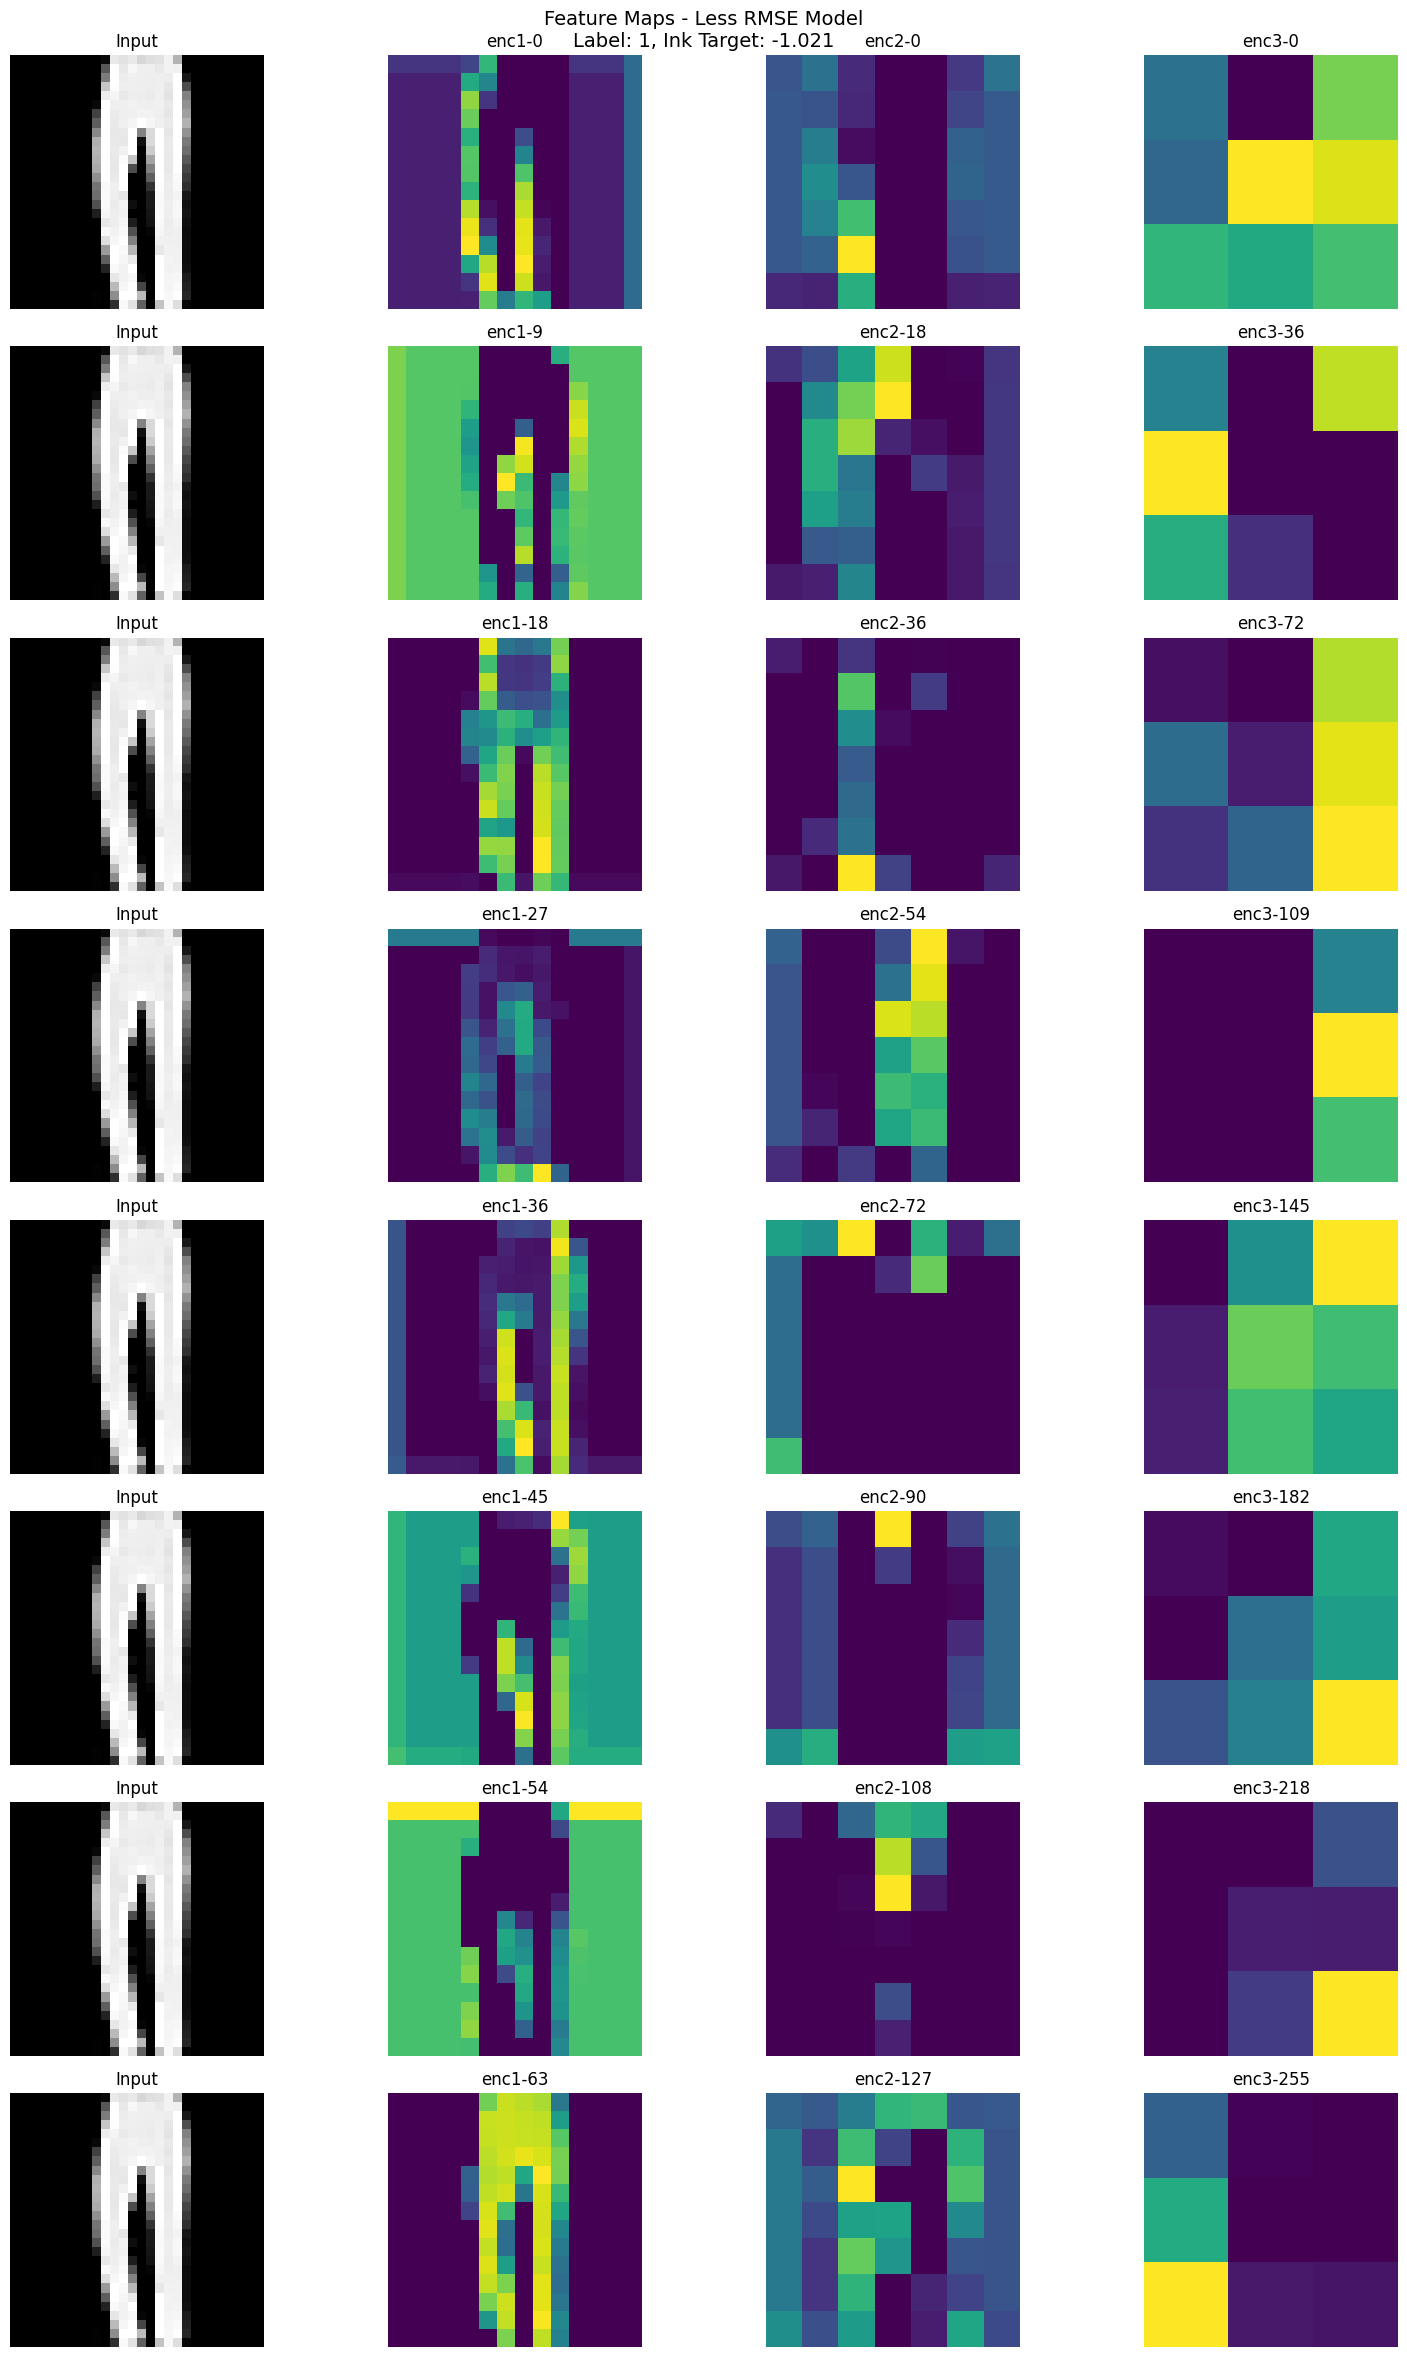


------------------------------------------------------------------------------------------------------------------------------------------------------



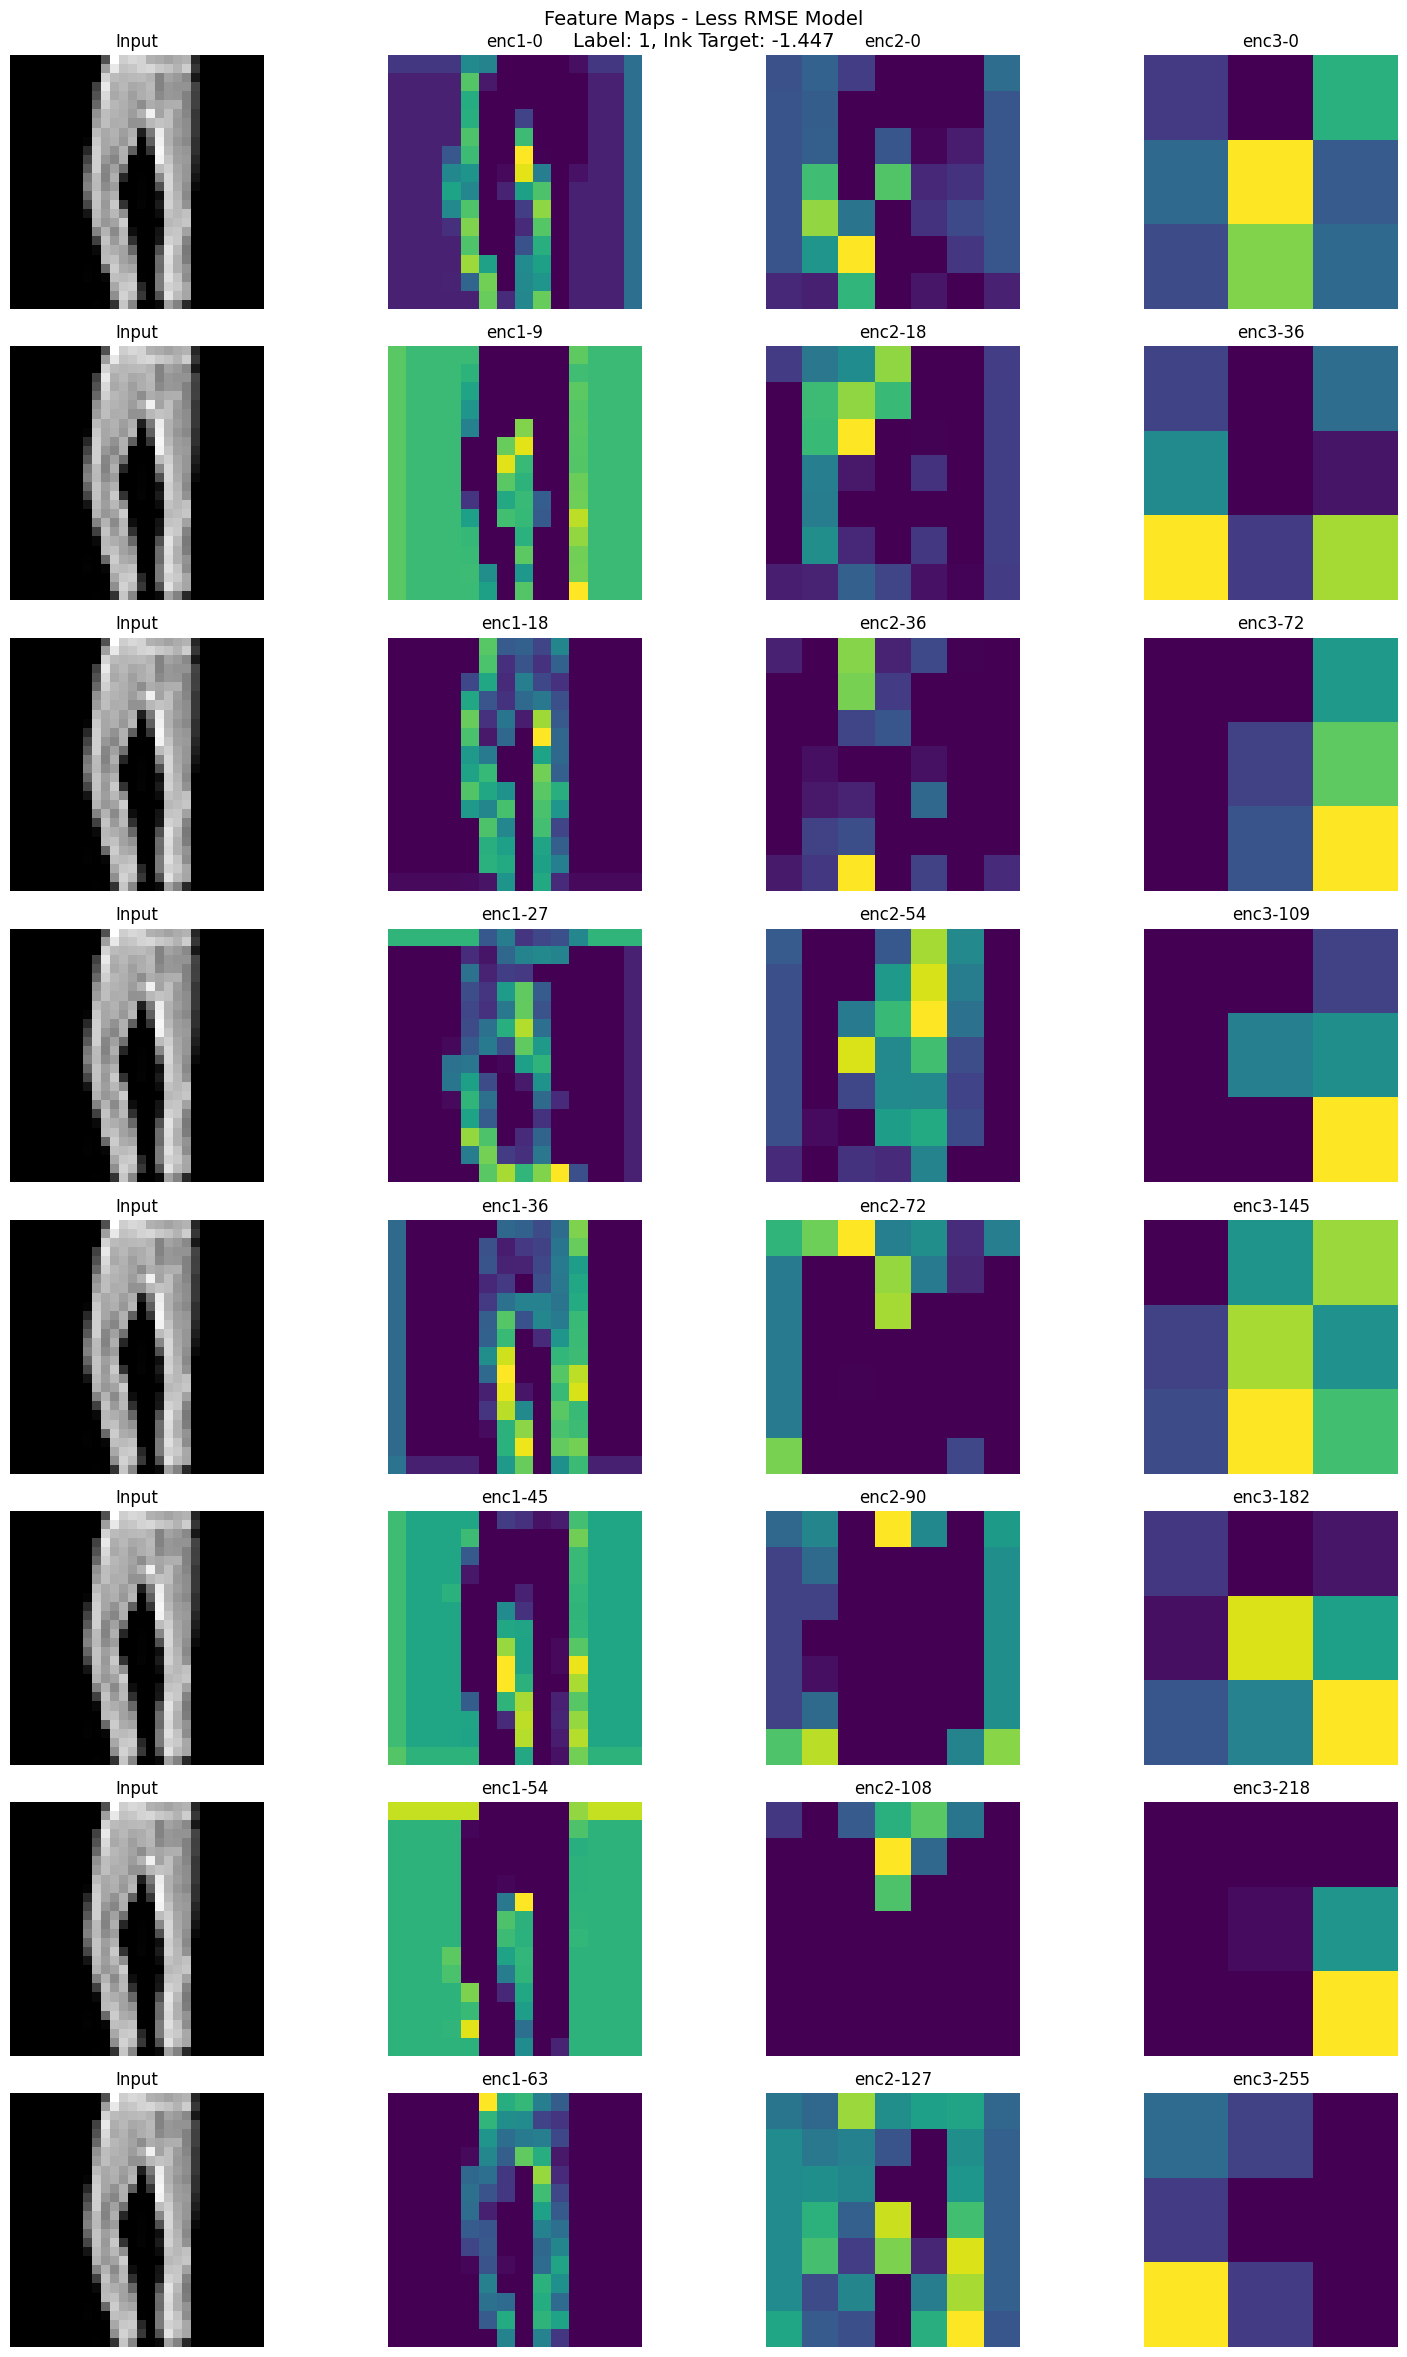


------------------------------------------------------------------------------------------------------------------------------------------------------



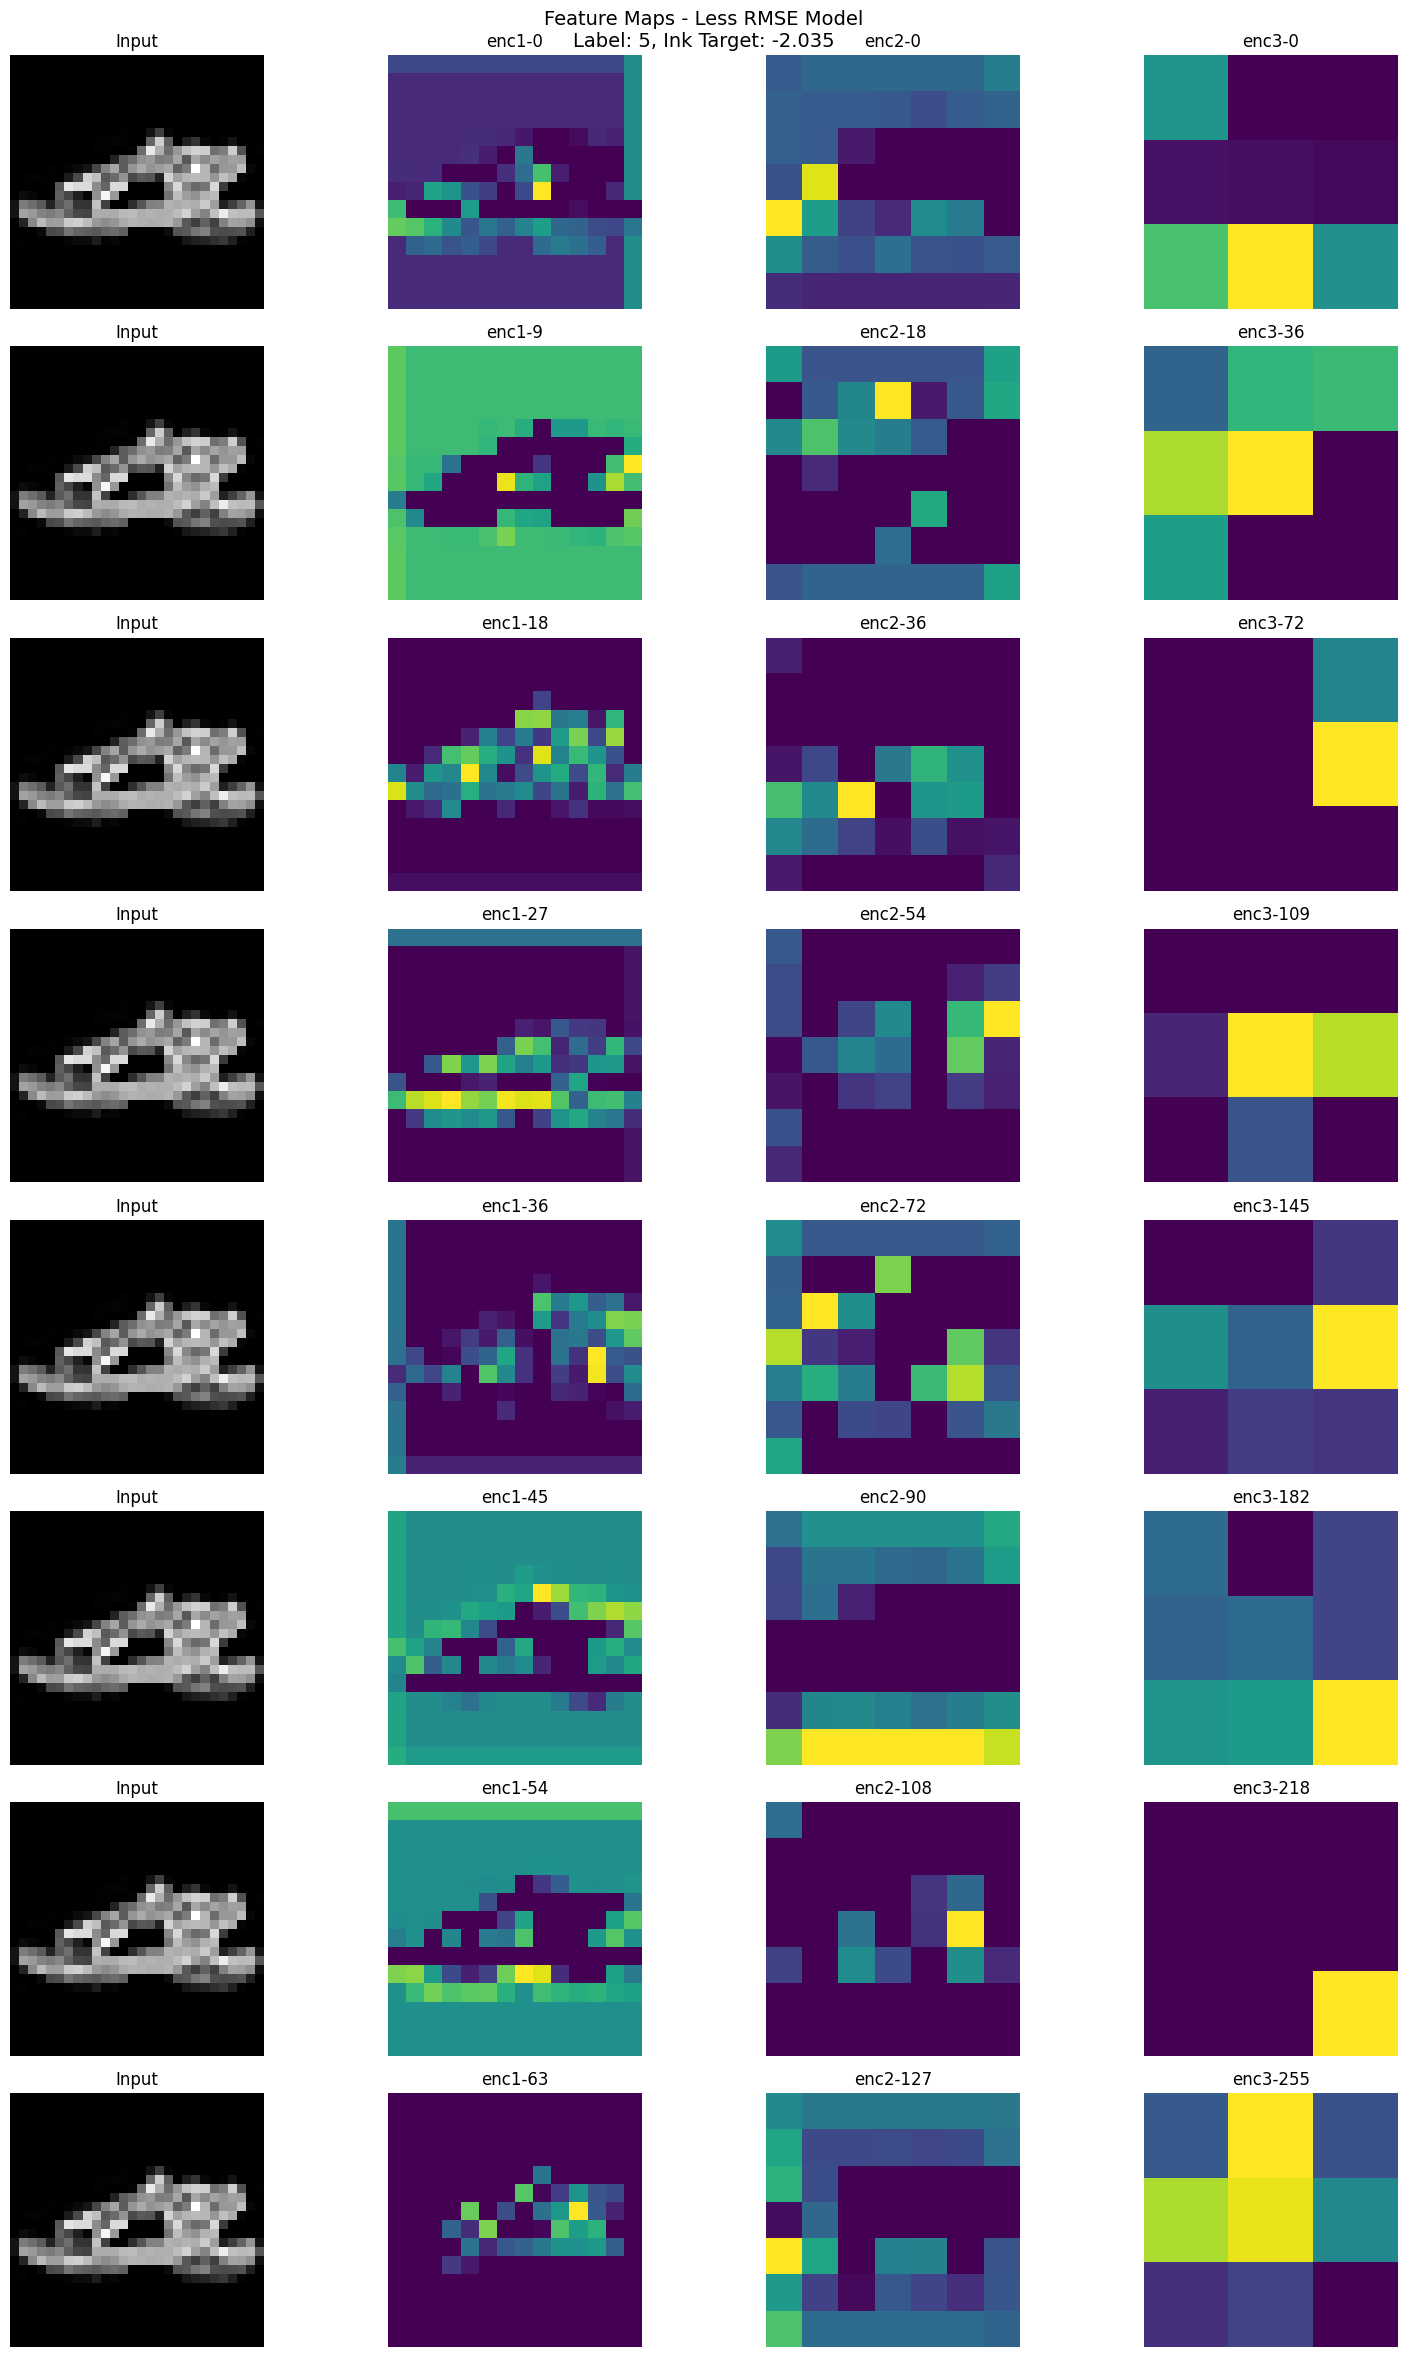


------------------------------------------------------------------------------------------------------------------------------------------------------



In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
visualize_feature_maps(less_rmse_model,test_loader,device,"Less RMSE Model",
                       num_images=3,num_features=8)

### Feature Map Interpretation – Multi-Task CNN

The model uses three convolution blocks (Enc1 , Enc2, Enc3) and i have visualized them for 3 test images per model.

**Layer Wise Interpretation**
- Encoder Block 1 :
  - Reacts strongly to simple edges and intensity transition boundaries
  - It highlights the outer structure of object
  - Still looks close to the original image (spatial detail is preserved)
  - Helps classification by distinguishing basic silhouettes
  - Helps ink regression by identifying where ink is concentrated at edges
  
- Encoder Block 2 :
  - Noise and Background starts to disappear
  - The model begins to detect texture patterns and shapes inside object
  - Individual regions (like thin or thick parts) become more prominent
  - Improves category separation among similar items (eg. trousers vs jeans)
  - Provides better signal about region-wise ink density and fabric texture

- Encoder Block 3 :
  - The feature maps now look blocky and very abstract
  - Spatial details are gone
  - The model focuses on the parts that are most useful for decision making
  - Critical for final classification
  - Helps ink regression by estimating total area / silhouette ink coverage


| Block | Feature Type | Spatial Detail | Semantic Meaning | Useful for |
|:------|:-------------|:---------------|:-----------------|:-----------|
| enc1 | Edges, basic constrasts | High | Low | Early signal extraction for both tasks |
| enc2 | Regional and texture features | Medium | Medium | Understanding structure & ink distribustion |
| enc3 | Sematic shape curves | Low | High | Final Classification & ink quantity reasoning |

## wandb Dashboard: [Dashboard Link](https://wandb.ai/nikhil_r_8074-iiit-hyderabad/SMAI-MultiTask-FashionMNIST/workspace?nw=nwusernikhilrepala8074)


## Report (PDF) : [Report Link](https://drive.google.com/file/d/1vX-ejYdC0m8baBmNx00siYRd_xgBUUo6/view?usp=sharing)